In [91]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import matplotlib

import sys
import os
parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(parent_dir)

from functions.read_g4bl_data import readTraceData, readDetData
from functions.set_plot_settings import setPlotSettings

setPlotSettings(font=True)

## Calculate one-turn transfer matrix

In [ ]:
data_x_pos = readDetData('zntuple_1turn_x_pos.txt')
data_x_pos_ref = data_x_pos[data_x_pos['EventID']==-1]
data_x_pos = data_x_pos[data_x_pos['EventID']==1]
data_x_neg = readDetData('zntuple_1turn_x_neg.txt')
data_x_neg_ref = data_x_neg[data_x_neg['EventID']==-1]
data_x_neg = data_x_neg[data_x_neg['EventID']==1]

data_y_pos = readDetData('zntuple_1turn_y_pos.txt')
data_y_pos_ref = data_y_pos[data_y_pos['EventID']==-1]
data_y_pos = data_y_pos[data_y_pos['EventID']==1]
data_y_neg = readDetData('zntuple_1turn_y_neg.txt')
data_y_neg_ref = data_y_neg[data_y_neg['EventID']==-1]
data_y_neg = data_y_neg[data_y_neg['EventID']==1]

data_xp_pos = readDetData('zntuple_1turn_xp_pos.txt')
data_xp_pos_ref = data_xp_pos[data_xp_pos['EventID']==-1]
data_xp_pos = data_xp_pos[data_xp_pos['EventID']==1]
data_xp_neg = readDetData('zntuple_1turn_xp_neg.txt')
data_xp_neg_ref = data_xp_neg[data_xp_neg['EventID']==-1]
data_xp_neg = data_xp_neg[data_xp_neg['EventID']==1]

data_yp_pos = readDetData('zntuple_1turn_yp_pos.txt')
data_yp_pos_ref = data_yp_pos[data_yp_pos['EventID']==-1]
data_yp_pos = data_yp_pos[data_yp_pos['EventID']==1]
data_yp_neg = readDetData('zntuple_1turn_yp_neg.txt')
data_yp_neg_ref = data_yp_neg[data_yp_neg['EventID']==-1]
data_yp_neg = data_yp_neg[data_yp_neg['EventID']==1]

data_p_pos = readDetData('zntuple_1turn_p_pos.txt')
data_p_pos_ref = data_p_pos[data_p_pos['EventID']==-1]
data_p_pos = data_p_pos[data_p_pos['EventID']==1]
data_p_neg = readDetData('zntuple_1turn_p_neg.txt')
data_p_neg_ref = data_p_neg[data_p_neg['EventID']==-1]
data_p_neg = data_p_neg[data_p_neg['EventID']==1]

# n.b. need to redo tracking sim for z b/c zntuple sampling --> use trace instead?
# data_z_pos = readDetData('zntuple_1turn_z_pos.txt')
# data_z_pos_ref = data_z_pos[data_z_pos['EventID']==-1]
# data_z_pos = data_z_pos[data_z_pos['EventID']==1]
# data_z_neg = readDetData('zntuple_1turn_z_neg.txt')
# data_z_neg_ref = data_z_neg[data_z_neg['EventID']==-1]
# data_z_neg = data_z_neg[data_z_neg['EventID']==1]

In [120]:
print('------------- x -------------')
print('reference: '+ str(data_x_pos_ref['x'].values[0]))
print('+ offset: '+ str(data_x_pos['x'].values[0]))
print('- offset: '+ str(data_x_neg['x'].values[0]))

print('------------- y -------------')
print('reference: '+ str(data_y_pos_ref['y'].values[0]))
print('+ offset: '+ str(data_y_pos['y'].values[0]))
print('- offset: '+ str(data_y_neg['y'].values[0]))

print('------------- xp -------------')
print('reference: '+ str(data_xp_pos_ref['xp'].values[0]))
print('+ offset: '+ str(data_xp_pos['xp'].values[0]))
print('- offset: '+ str(data_xp_neg['xp'].values[0]))

print('------------- yp -------------')
print('reference: '+ str(data_yp_pos_ref['yp'].values[0]))
print('+ offset: '+ str(data_yp_pos['yp'].values[0]))
print('- offset: '+ str(data_yp_neg['yp'].values[0]))

print('------------- p -------------')
print('reference: '+ str(data_p_pos_ref['ptotal'].values[0]))
print('+ offset: '+ str(data_p_pos['ptotal'].values[0]))
print('- offset: '+ str(data_p_neg['ptotal'].values[0]))

# print('------------- z -------------')
# print('reference: '+ str(data_z_pos_ref['z'].values[0]))
# print('+ offset: '+ str(data_z_pos['z'].values[0]))
# print('- offset: '+ str(data_z_neg['z'].values[0]))

------------- x -------------
reference: 6.28007
+ offset: 6.28635
- offset: 6.27378
------------- y -------------
reference: 12.9029
+ offset: 12.9158
- offset: 12.89
------------- xp -------------
reference: 0.052139093677378
+ offset: 0.05219144258074856
- offset: 0.0520875070117798
------------- yp -------------
reference: -0.02557832158025483
+ offset: -0.02560399272774625
- offset: -0.025552778668162513
------------- p -------------
reference: 200.00042351473883
+ offset: 200.19976059386883
- offset: 199.8000881177273


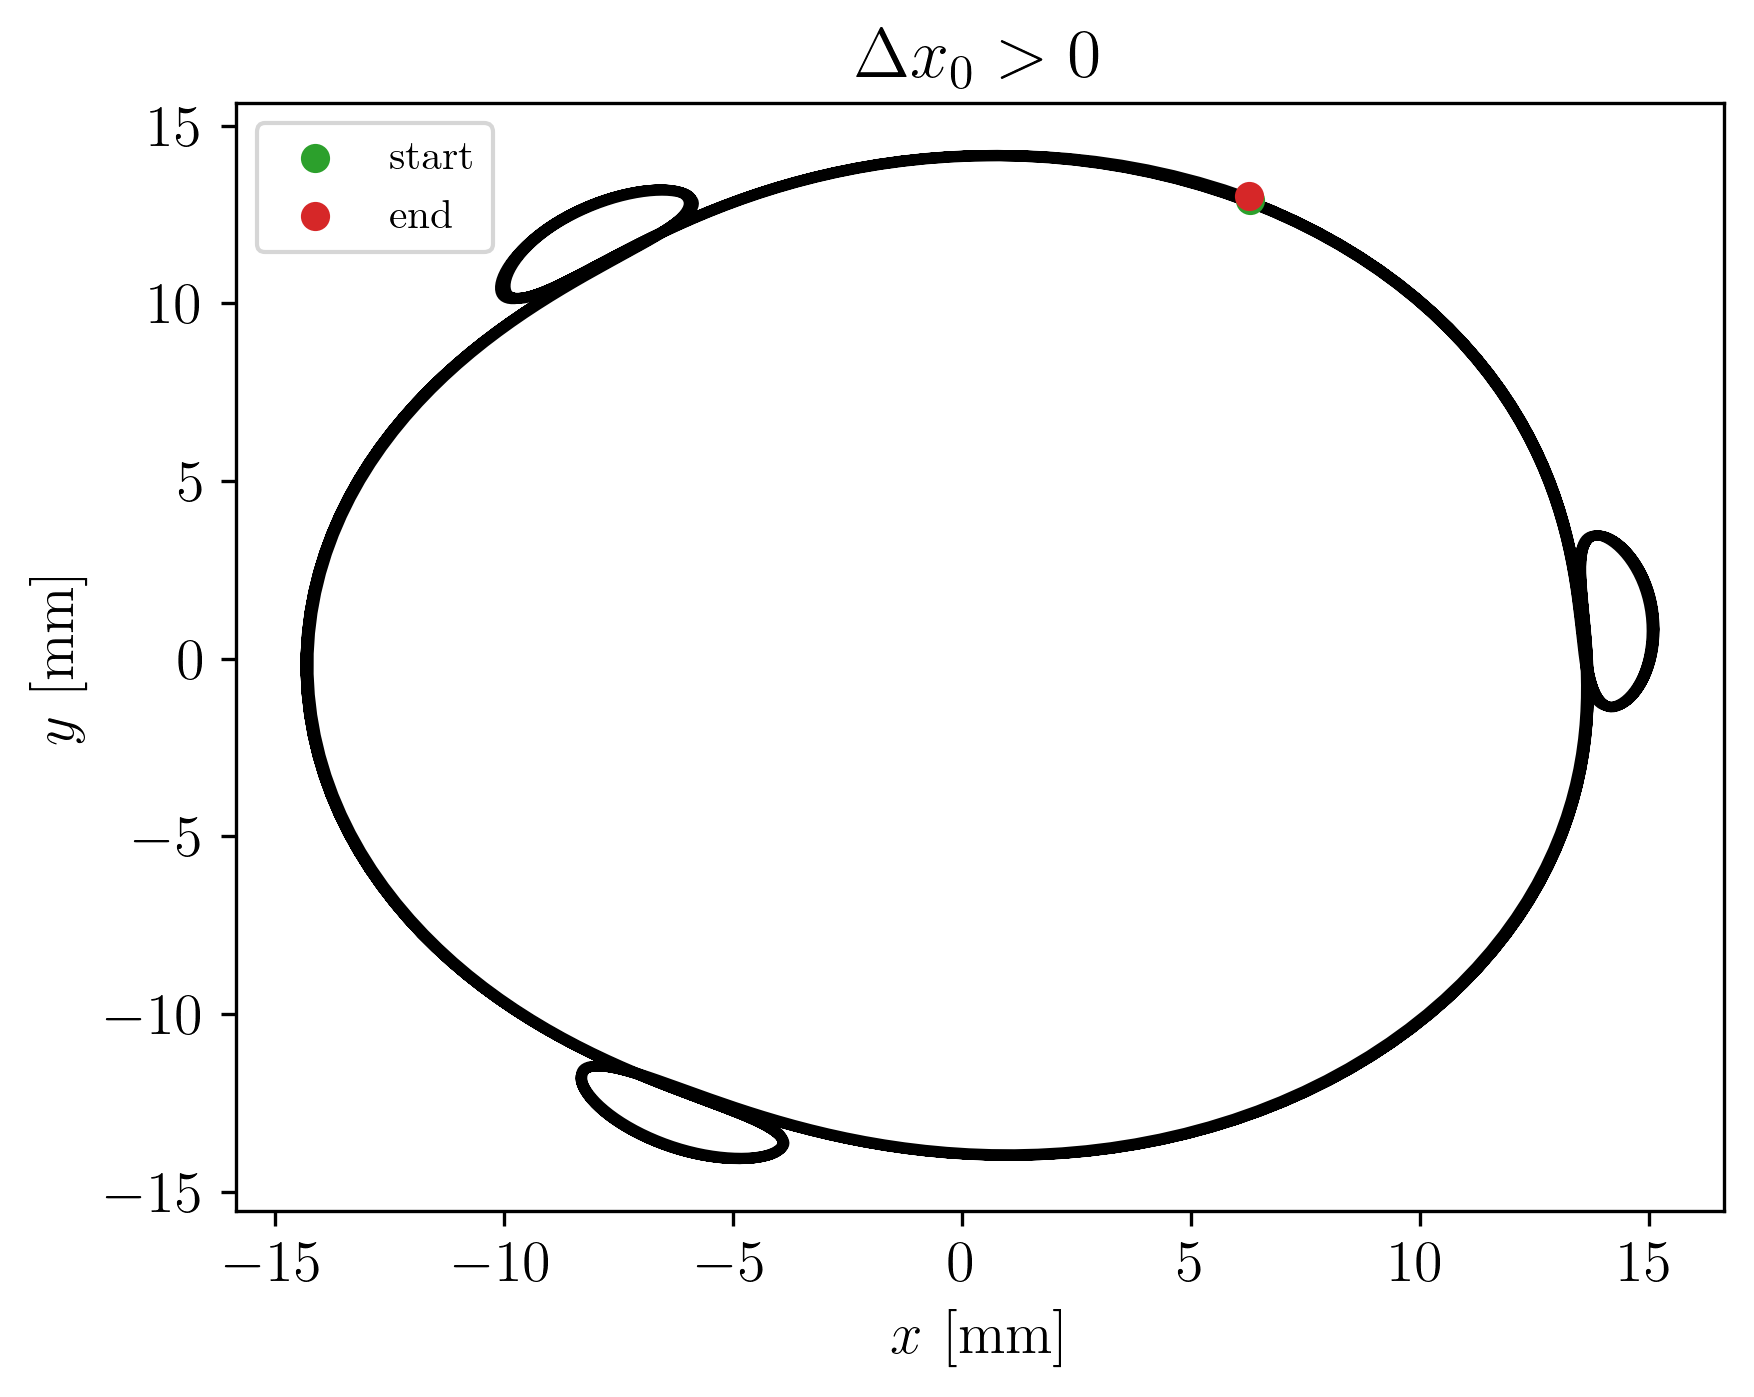

In [81]:
plt.scatter(data_x_pos['x'].values[0],data_x_pos['y'].values[0], label='start', color='tab:green')
# plt.scatter(data_x_pos_ref['x'].values[0],data_x_pos_ref['y'].values[0])
plt.scatter(data_x_pos['x'].values[-1],data_x_pos['y'].values[-1], label = 'end', color='tab:red')
# plt.scatter(data_x_pos_ref['x'].values[-1],data_x_pos_ref['y'].values[-1])
plt.plot(data_x_pos_ref['x'].values, data_x_pos_ref['y'].values, zorder=-1, color='black')
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 > 0$');

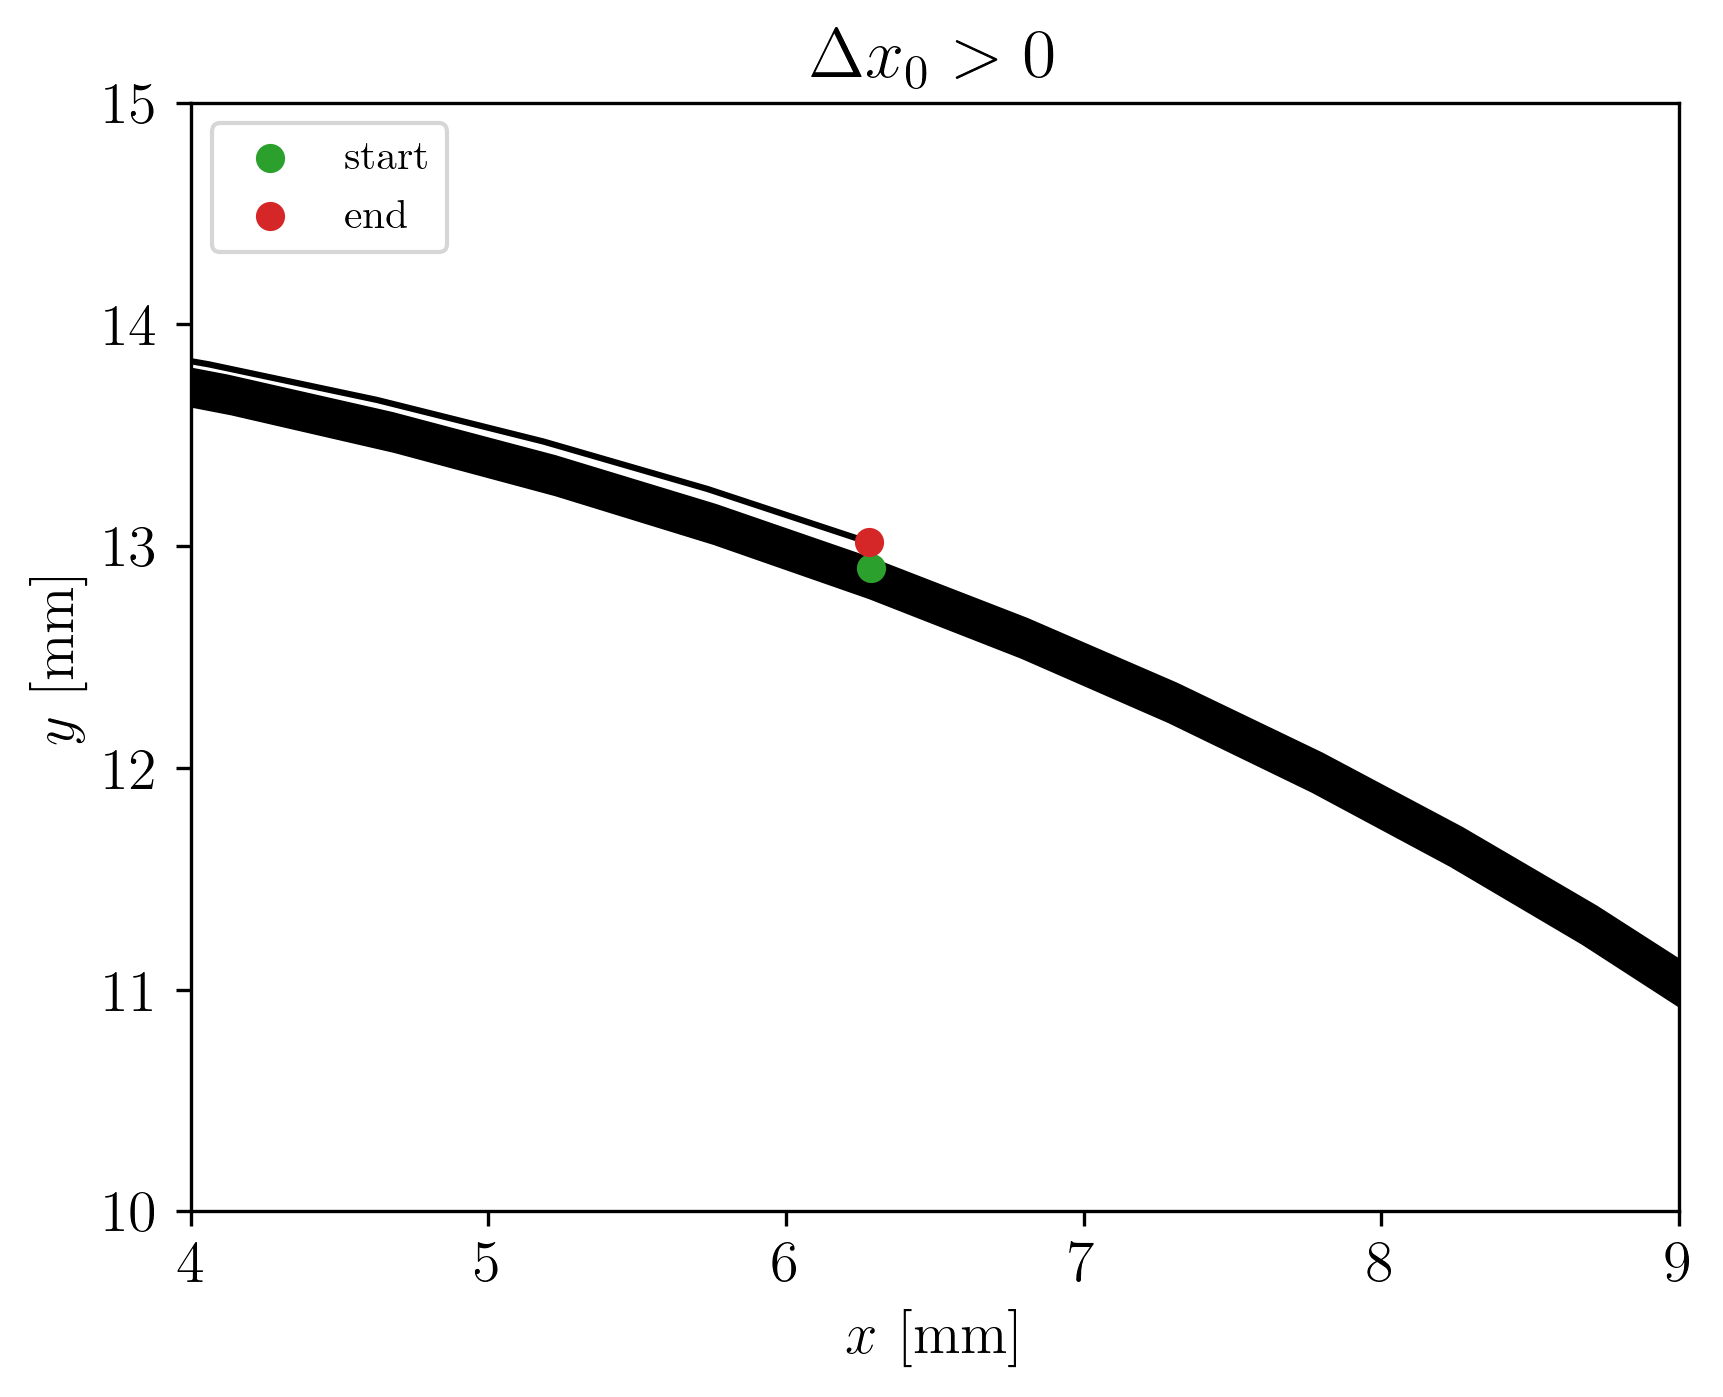

In [82]:
plt.scatter(data_x_pos['x'].values[0],data_x_pos['y'].values[0], label='start', color='tab:green')
# plt.scatter(data_x_pos_ref['x'].values[0],data_x_pos_ref['y'].values[0])
plt.scatter(data_x_pos['x'].values[-1],data_x_pos['y'].values[-1], label = 'end', color='tab:red')
# plt.scatter(data_x_pos_ref['x'].values[-1],data_x_pos_ref['y'].values[-1])
plt.plot(data_x_pos_ref['x'].values, data_x_pos_ref['y'].values, zorder=-1, color='black')
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim((4,9))
plt.ylim((10,15))
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 > 0$');

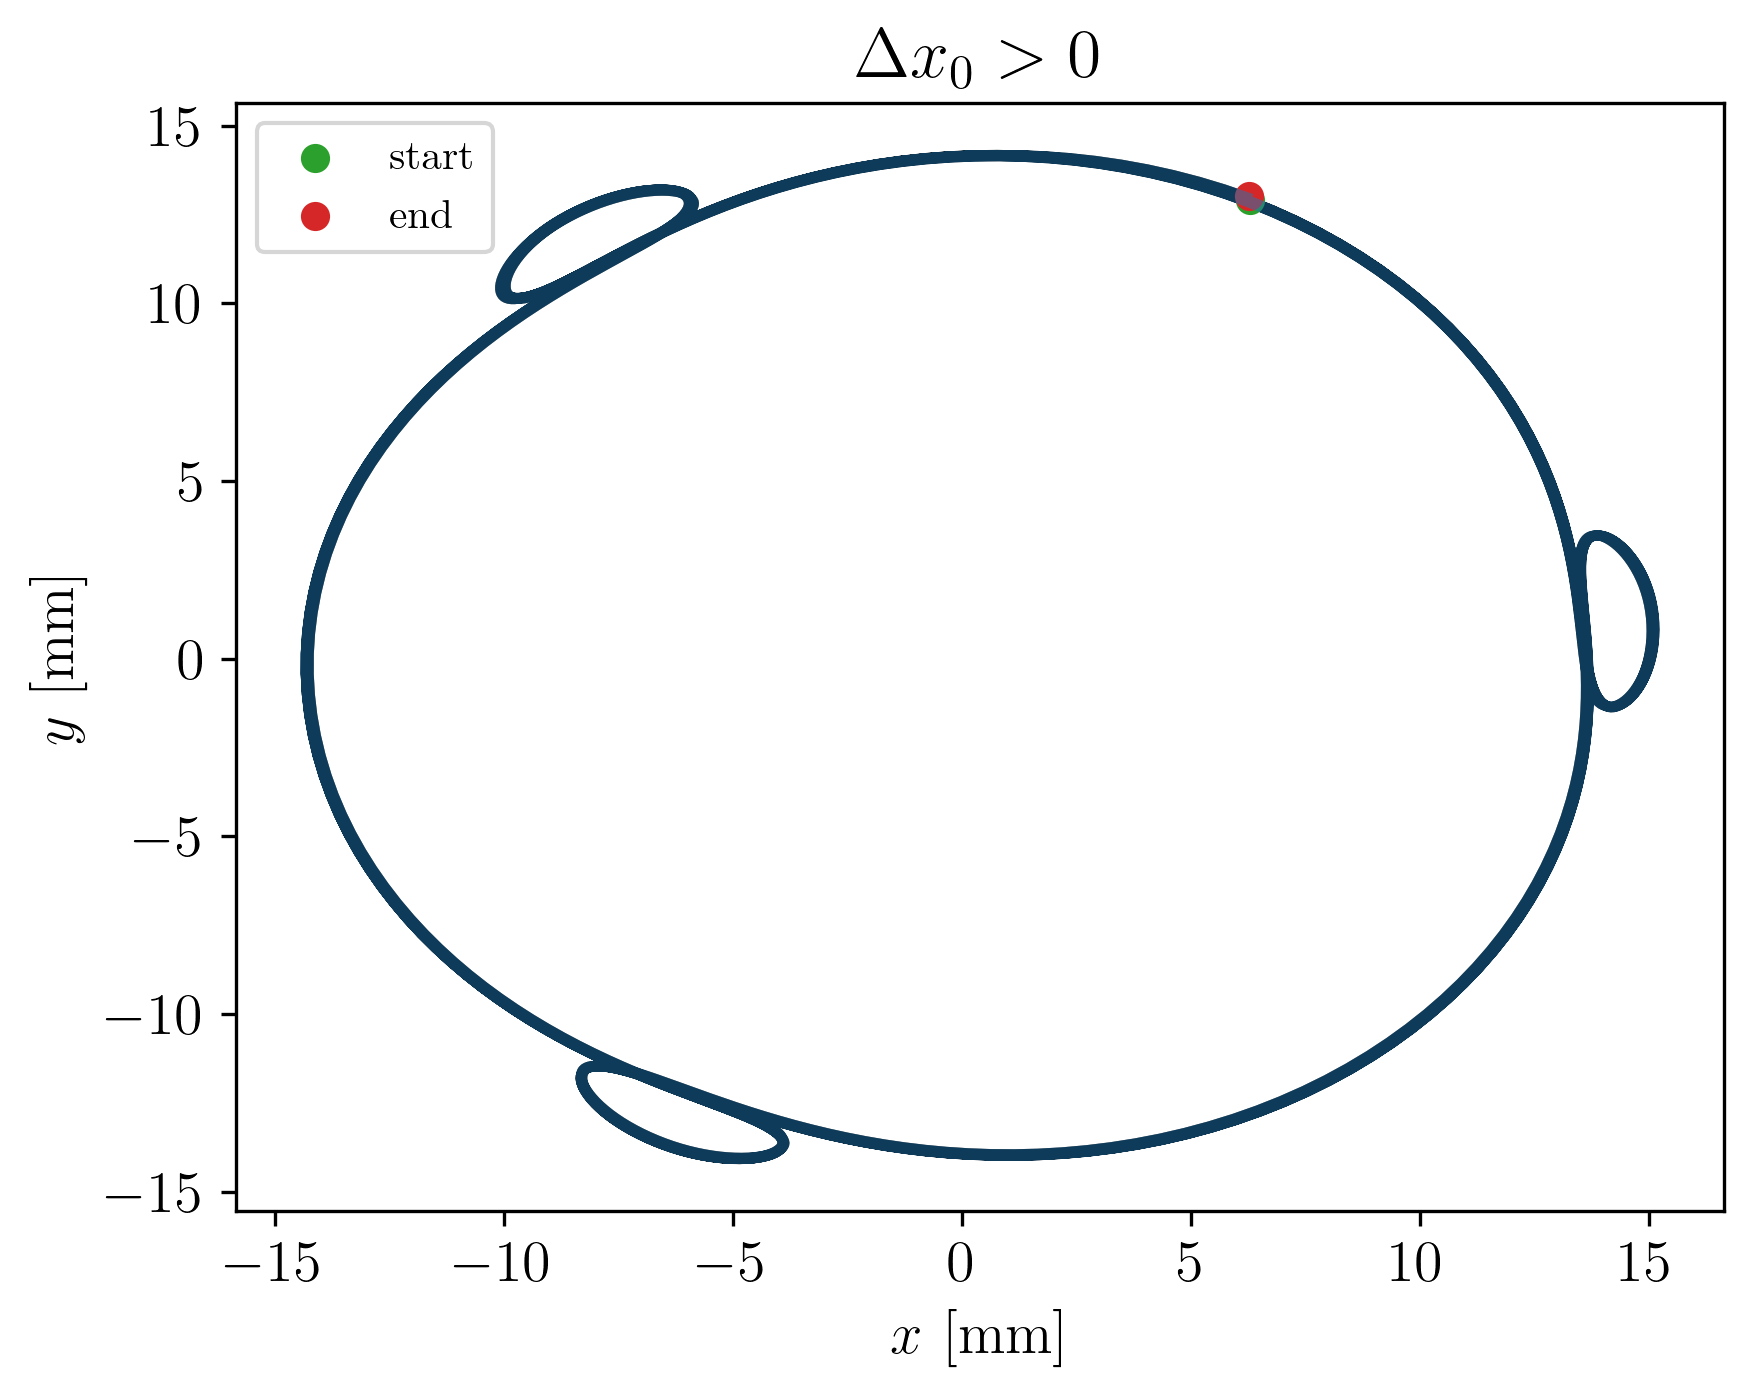

In [83]:
plt.scatter(data_x_pos['x'].values[0],data_x_pos['y'].values[0], label='start', color='tab:green')
# plt.scatter(data_x_pos_ref['x'].values[0],data_x_pos_ref['y'].values[0])
plt.scatter(data_x_pos['x'].values[-1],data_x_pos['y'].values[-1], label = 'end', color='tab:red')
# plt.scatter(data_x_pos_ref['x'].values[-1],data_x_pos_ref['y'].values[-1])
plt.plot(data_x_pos_ref['x'].values, data_x_pos_ref['y'].values, zorder=-1, color='black')
plt.plot(data_x_pos['x'].values, data_x_pos['y'].values, alpha=0.5)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 > 0$');

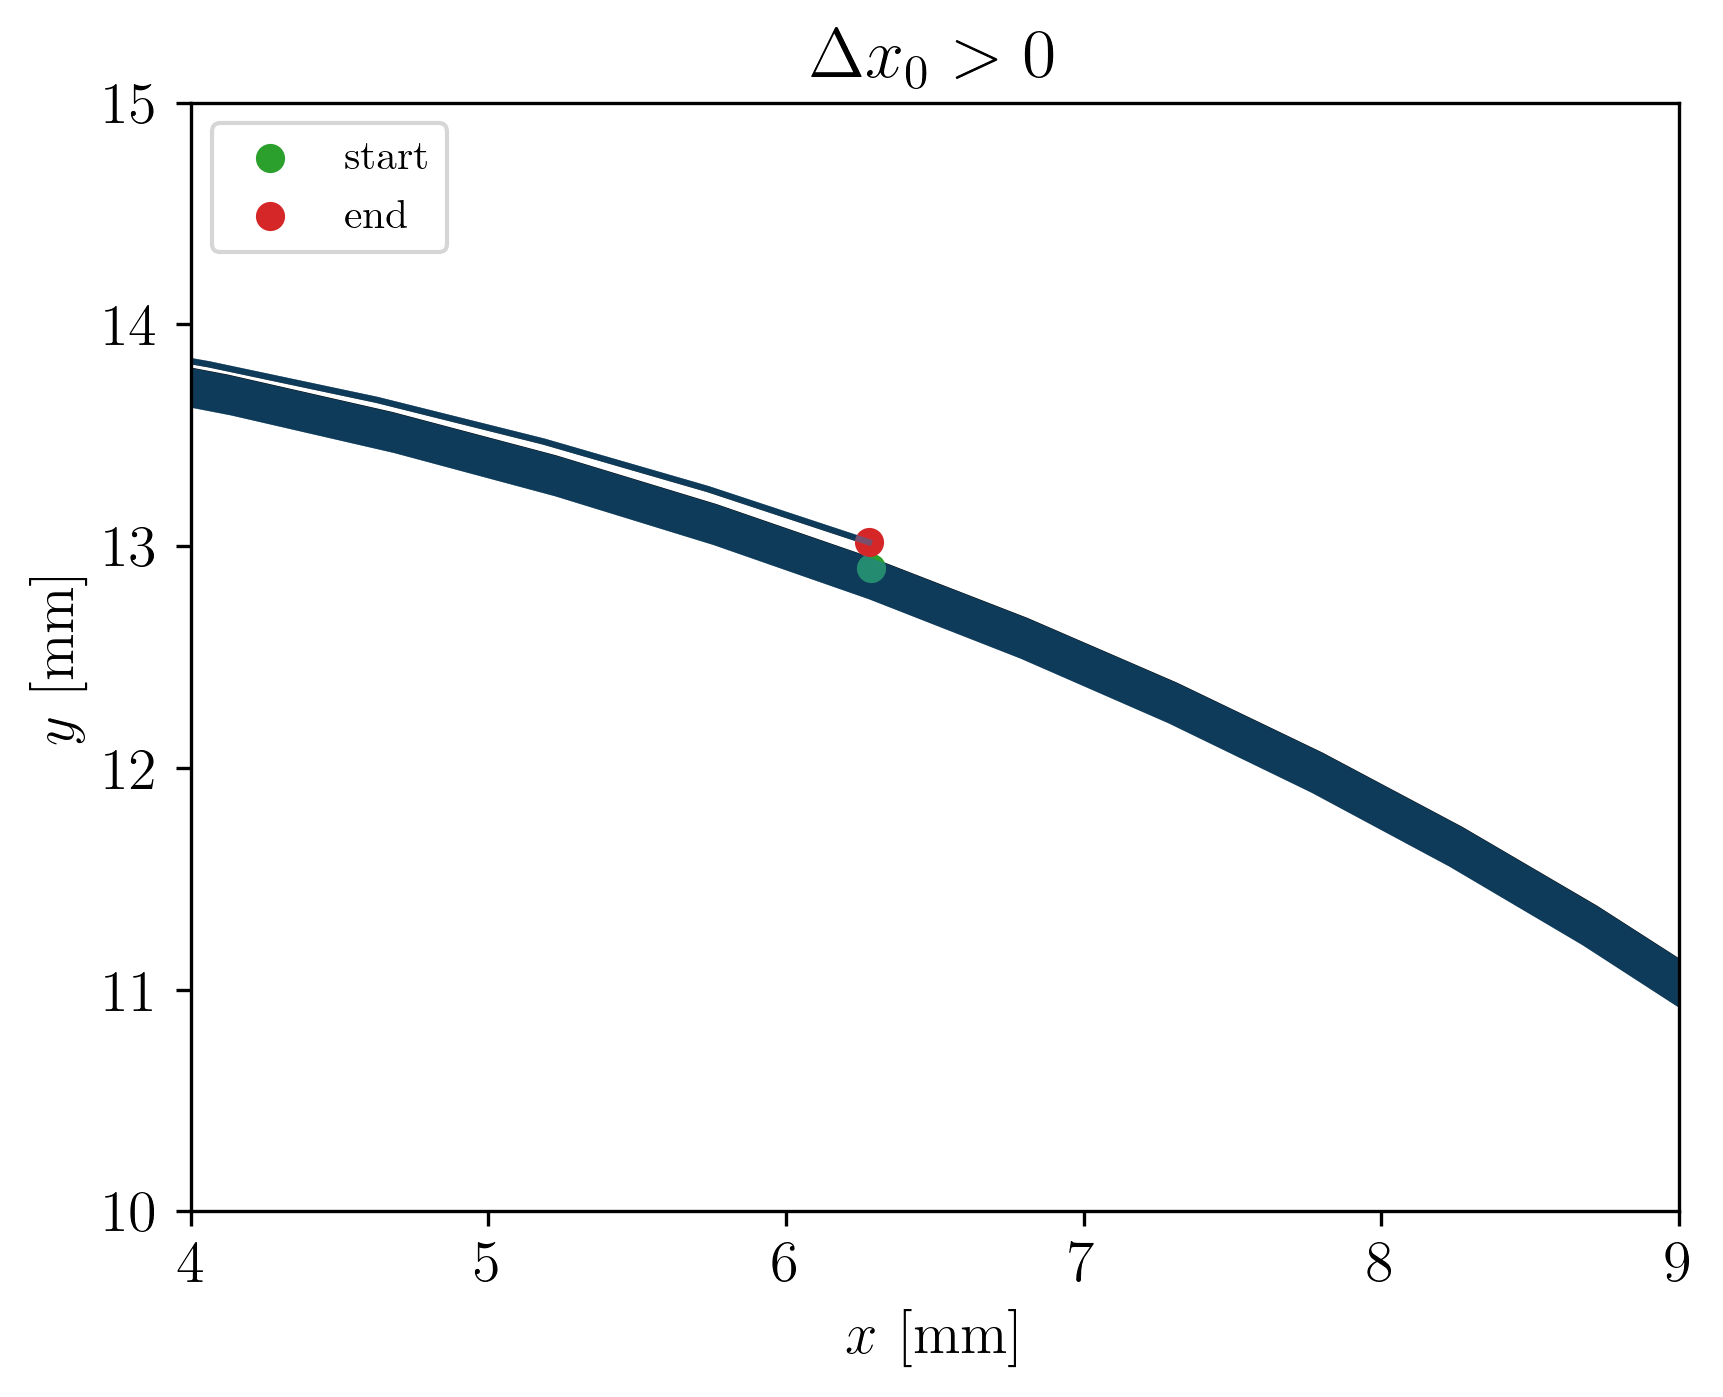

In [84]:
plt.scatter(data_x_pos['x'].values[0],data_x_pos['y'].values[0], label='start', color='tab:green')
# plt.scatter(data_x_pos_ref['x'].values[0],data_x_pos_ref['y'].values[0])
plt.scatter(data_x_pos['x'].values[-1],data_x_pos['y'].values[-1], label = 'end', color='tab:red')
# plt.scatter(data_x_pos_ref['x'].values[-1],data_x_pos_ref['y'].values[-1])
plt.plot(data_x_pos_ref['x'].values, data_x_pos_ref['y'].values, zorder=-1, color='black')
plt.plot(data_x_pos['x'].values, data_x_pos['y'].values, alpha=0.5)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim((4,9))
plt.ylim((10,15))
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 > 0$');

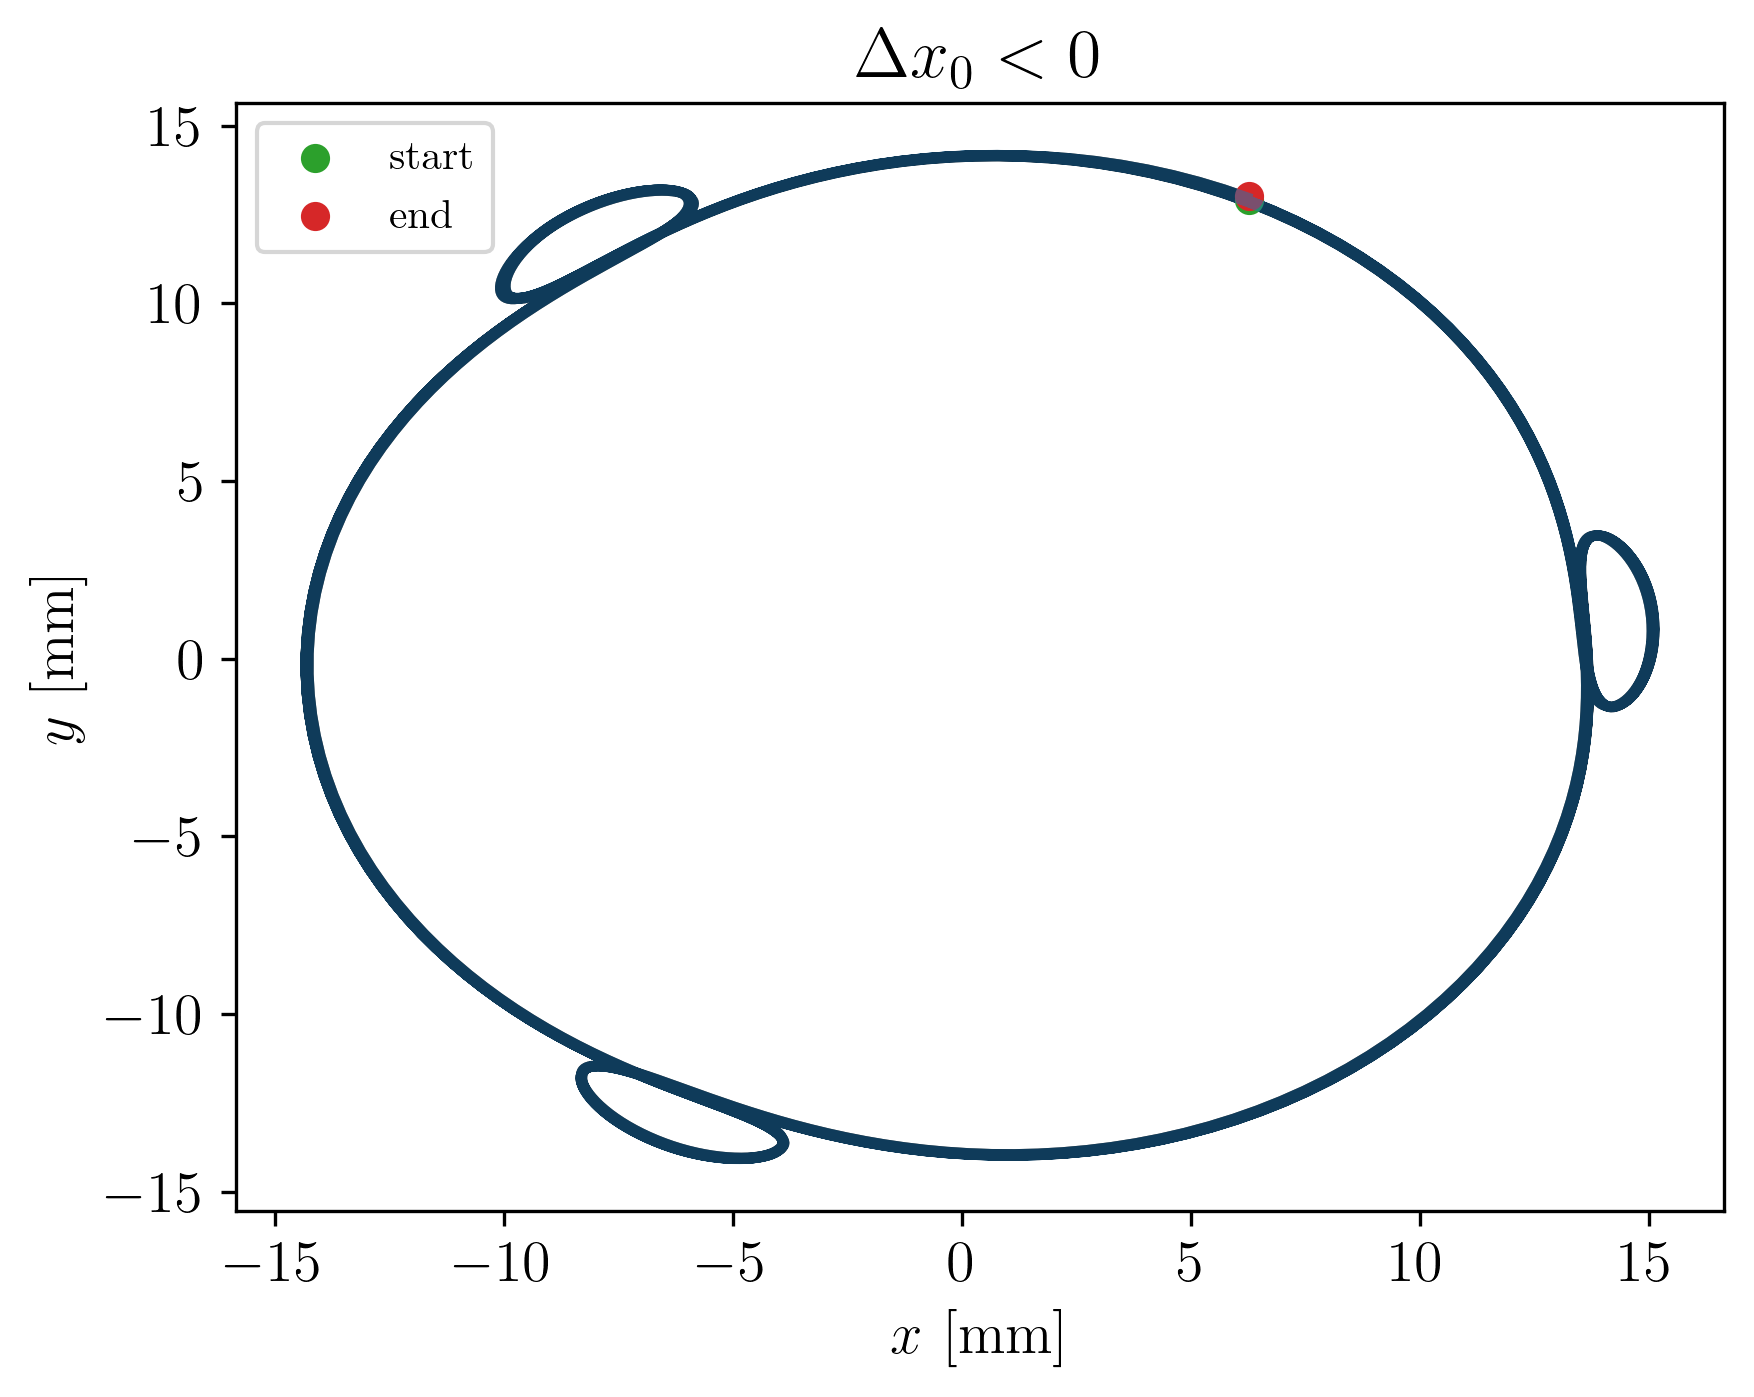

In [85]:
plt.scatter(data_x_neg['x'].values[0],data_x_neg['y'].values[0], label='start', color='tab:green')
plt.scatter(data_x_neg['x'].values[-1],data_x_neg['y'].values[-1], label = 'end', color='tab:red')
plt.plot(data_x_neg_ref['x'].values, data_x_neg_ref['y'].values, zorder=-1, color='black')
plt.plot(data_x_neg['x'].values, data_x_neg['y'].values, alpha=0.5)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 < 0$');

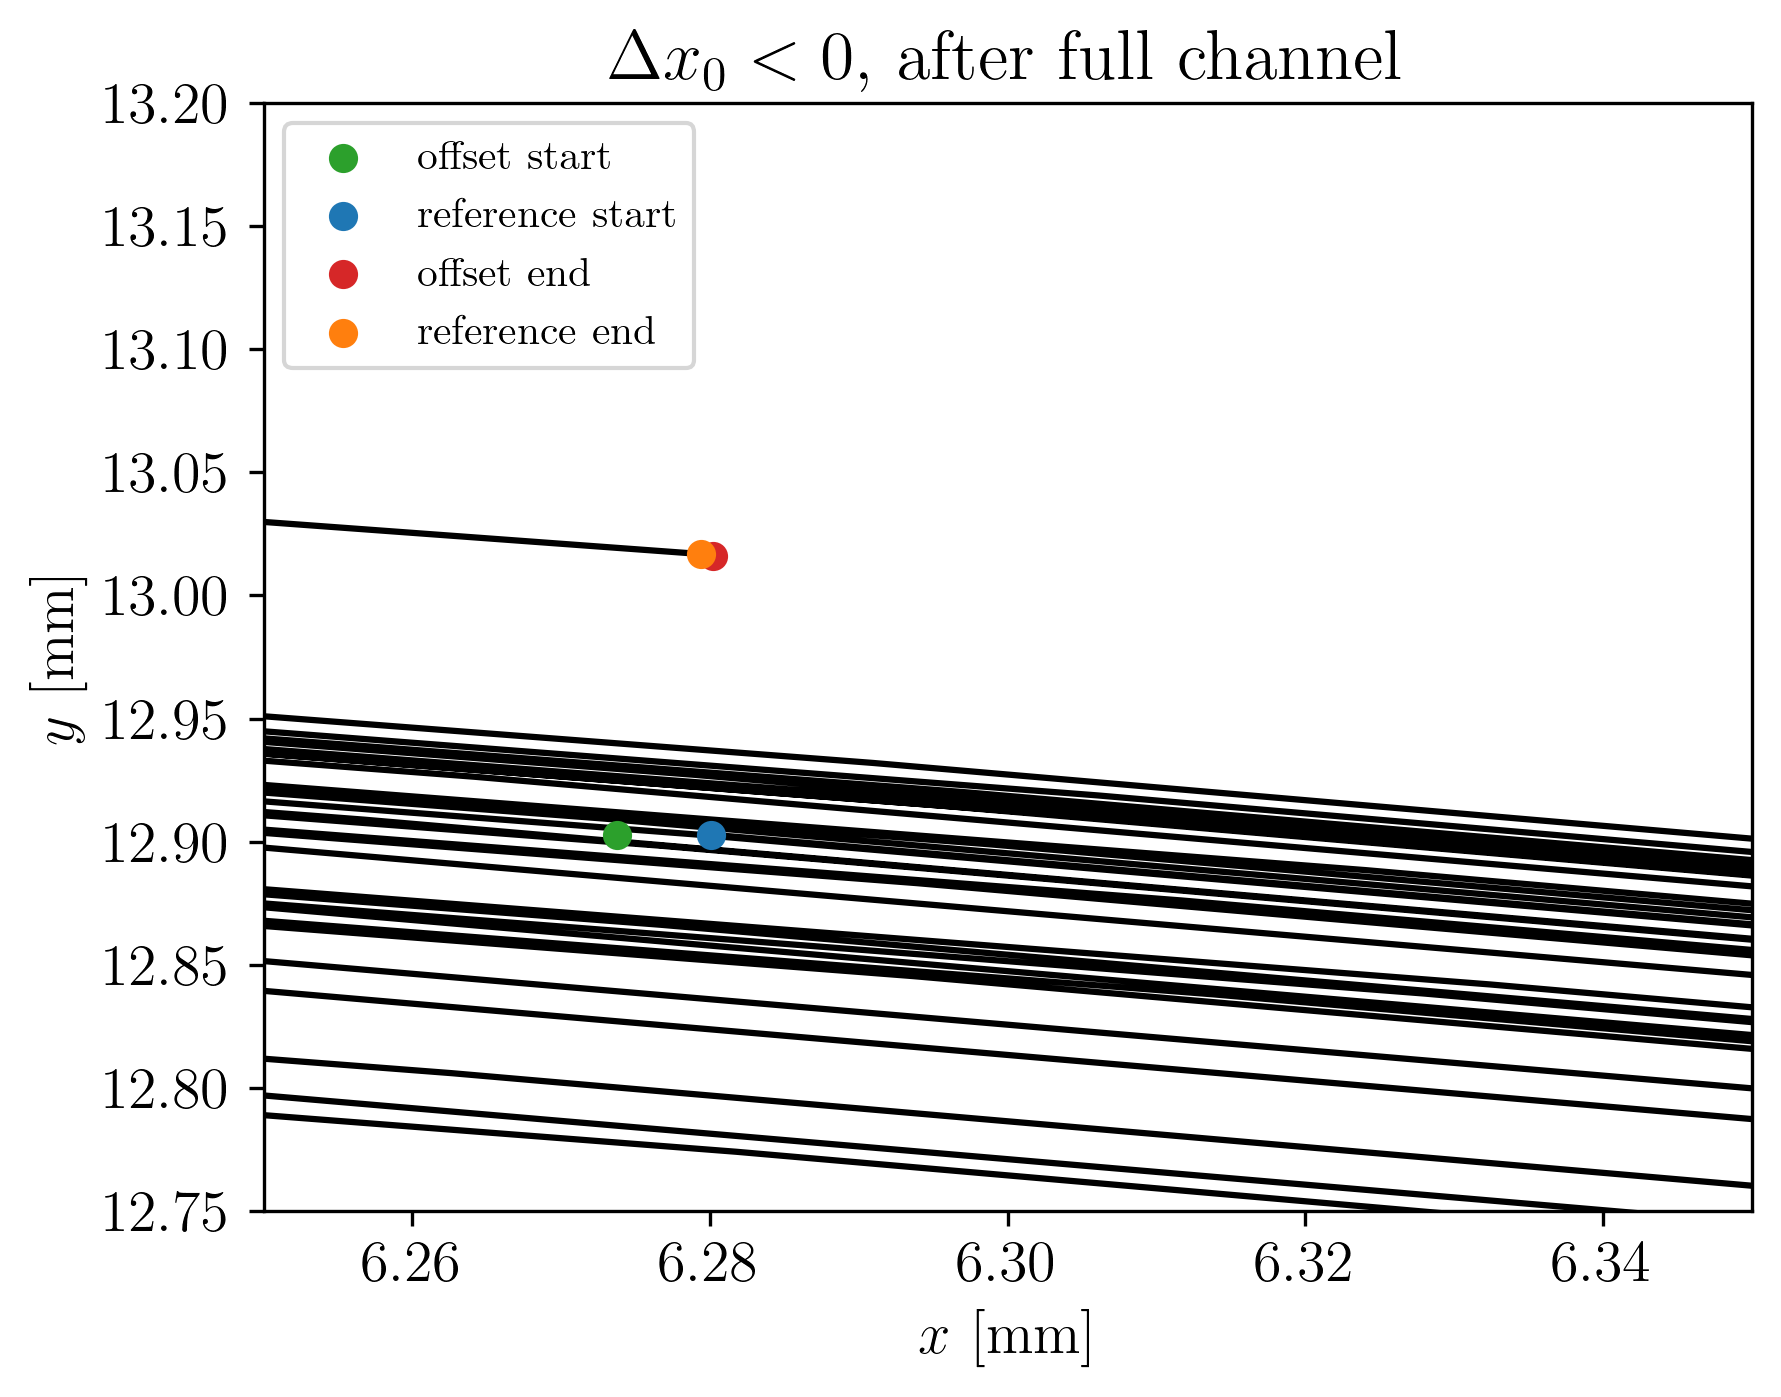

In [125]:
plt.scatter(data_x_neg['x'].values[0],data_x_neg['y'].values[0], label='offset start', color='tab:green')
plt.scatter(data_x_neg_ref['x'].values[0],data_x_neg_ref['y'].values[0], label='reference start')
plt.scatter(data_x_neg['x'].values[-1],data_x_neg['y'].values[-1], label = 'offset end', color='tab:red')
plt.scatter(data_x_neg_ref['x'].values[-1],data_x_neg_ref['y'].values[-1], label='reference end')
plt.plot(data_x_neg_ref['x'].values, data_x_neg_ref['y'].values, zorder=-1, color='black')
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim((6.25,6.35))
plt.ylim((12.75,13.2))
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 < 0$, after full channel');

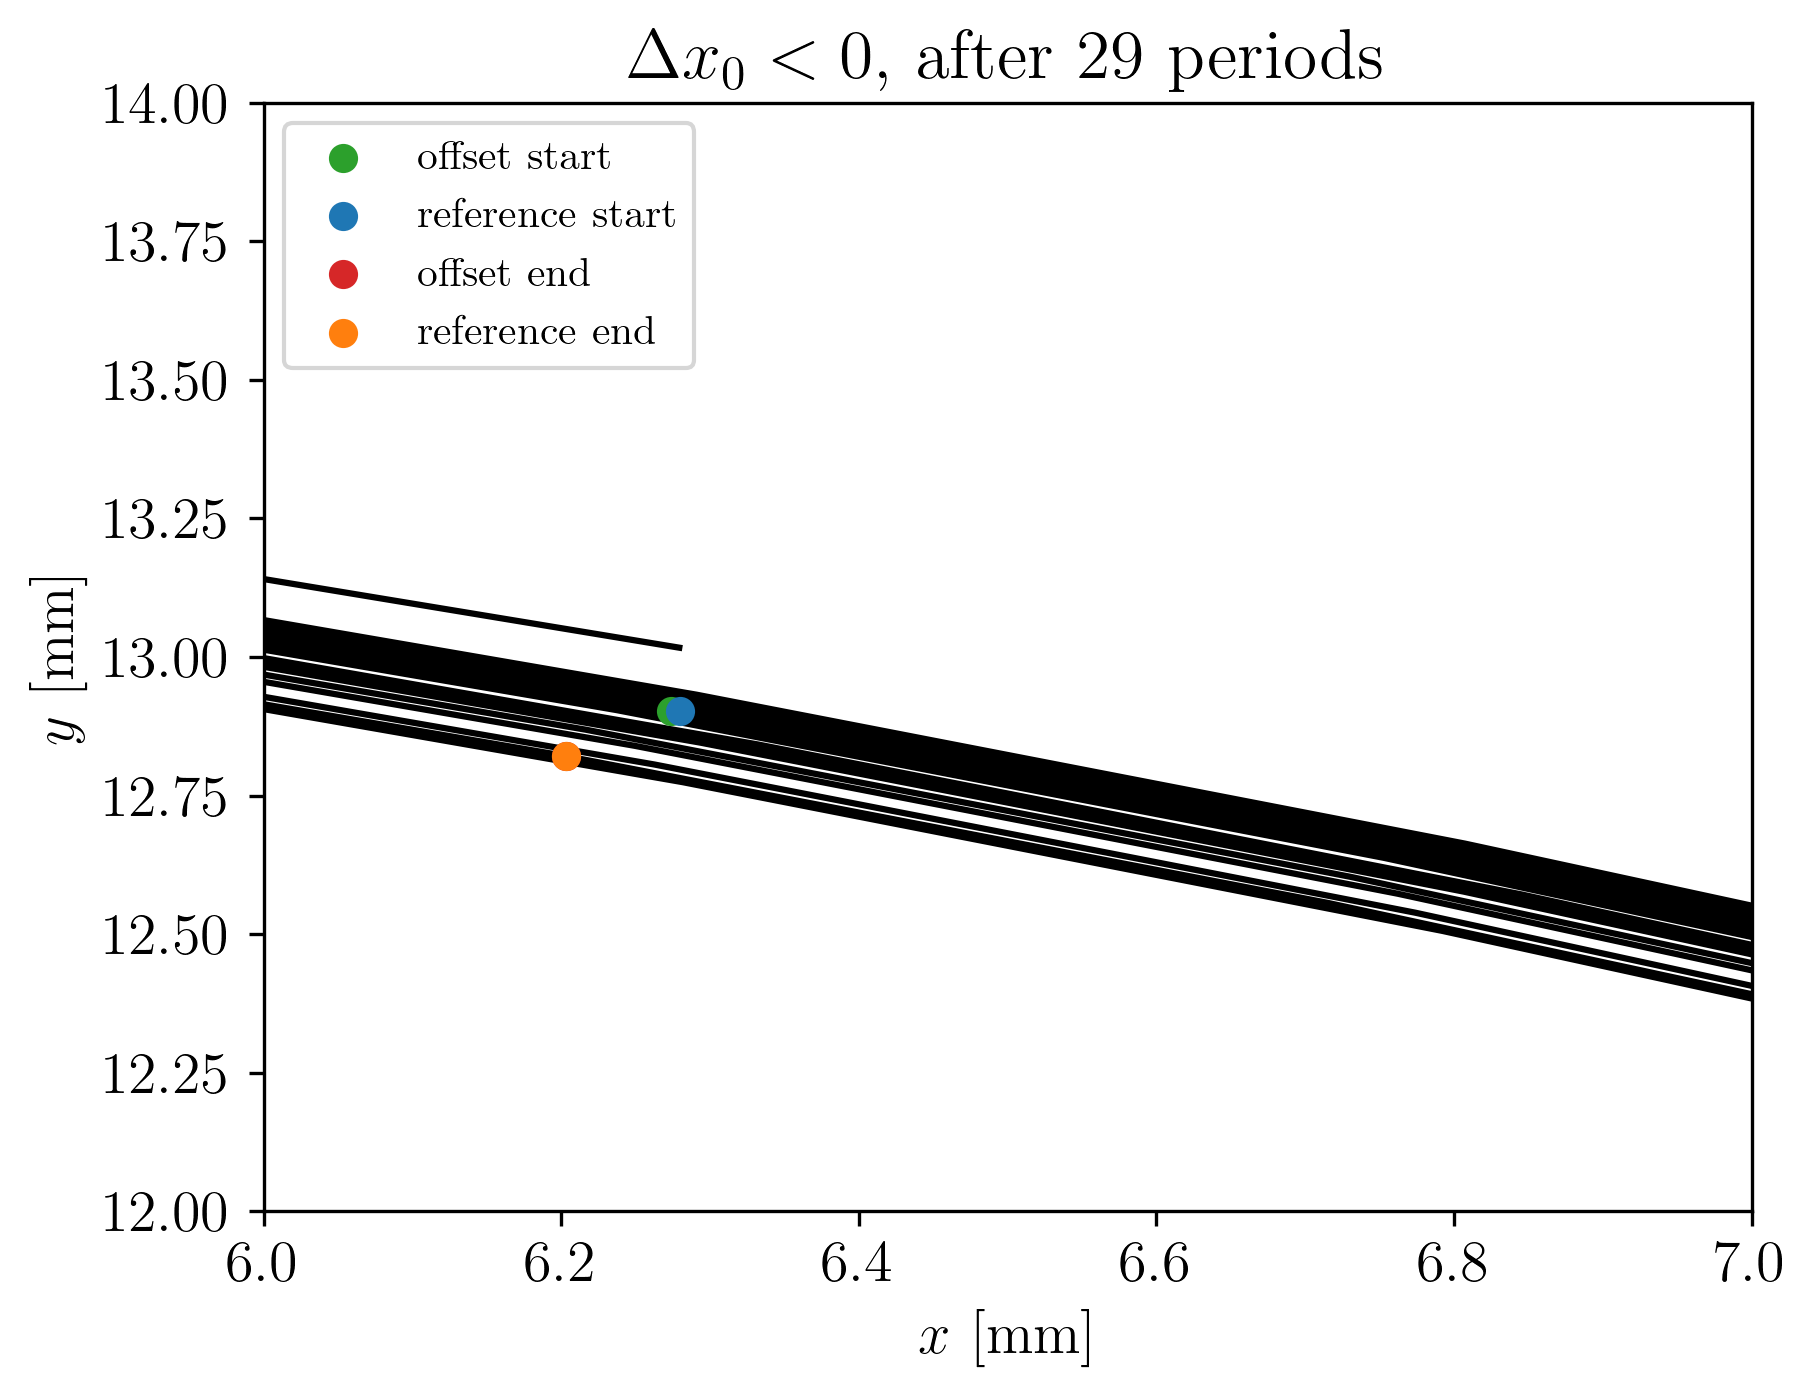

In [124]:
plt.scatter(data_x_neg['x'].values[0],data_x_neg['y'].values[0], label='offset start', color='tab:green')
plt.scatter(data_x_neg_ref['x'].values[0],data_x_neg_ref['y'].values[0], label='reference start')
plt.scatter(data_x_neg['x'].values[-421],data_x_neg['y'].values[-421], label = 'offset end', color='tab:red')
plt.scatter(data_x_neg_ref['x'].values[-421],data_x_neg_ref['y'].values[-421], label='reference end')
plt.plot(data_x_neg_ref['x'].values, data_x_neg_ref['y'].values, zorder=-1, color='black')
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim((6,7))
plt.ylim((12,14))
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 < 0$, after 29 periods');

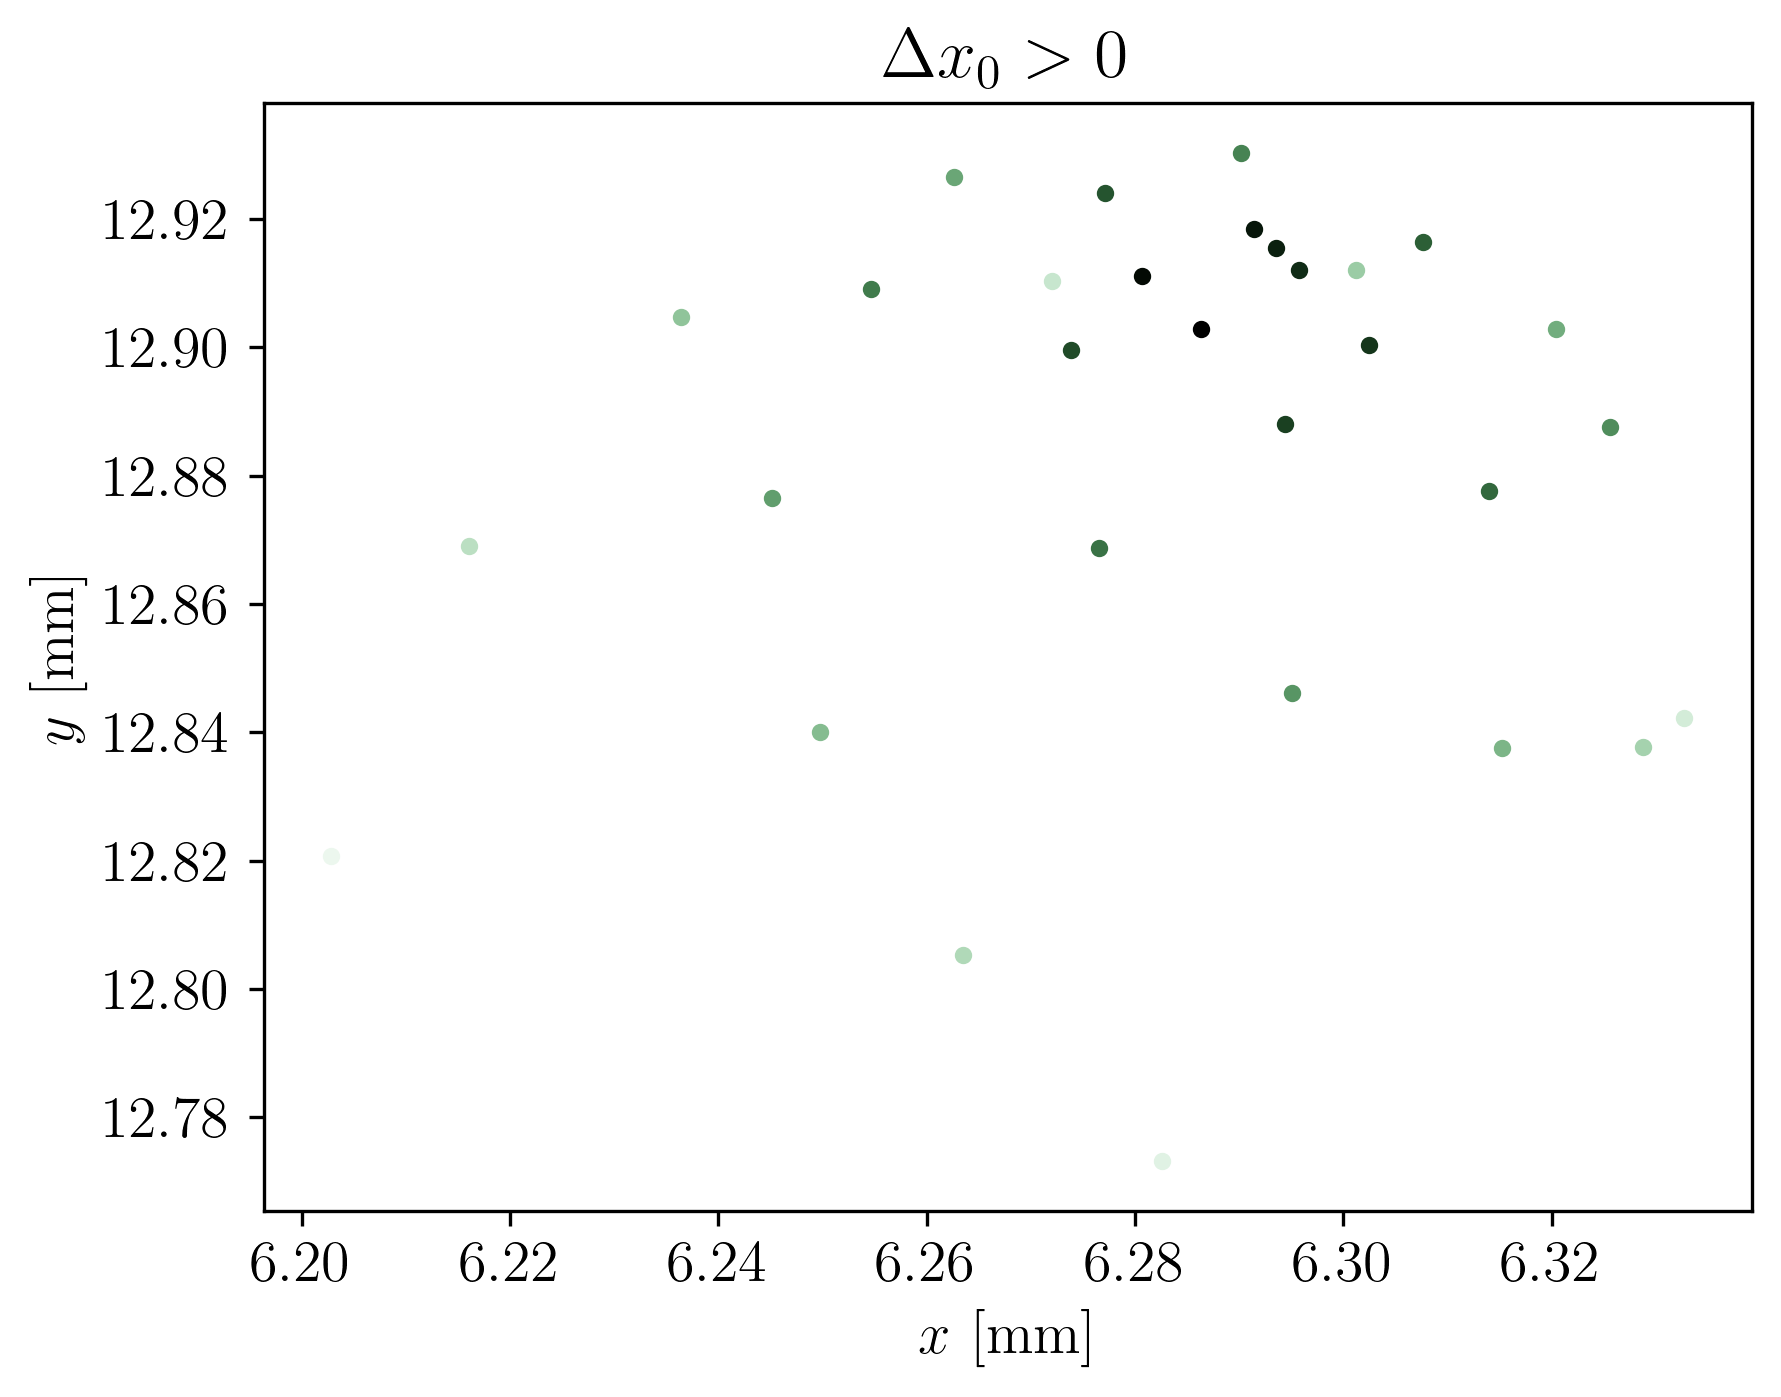

In [99]:
cmap = sns.cubehelix_palette(start=2, rot=0, dark=0, light=.95, reverse=True, as_cmap=True)
norm = matplotlib.colors.Normalize(vmin=0, vmax=29)
colors = cmap(norm(range(30)))
for i in range(30):
    plt.scatter(data_x_pos['x'].values[i*420],data_x_pos['y'].values[i*420], color=colors[i], s=10)
    # print(data_x_pos['z'].values[i*420])
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.title('$\Delta x_0 > 0$');

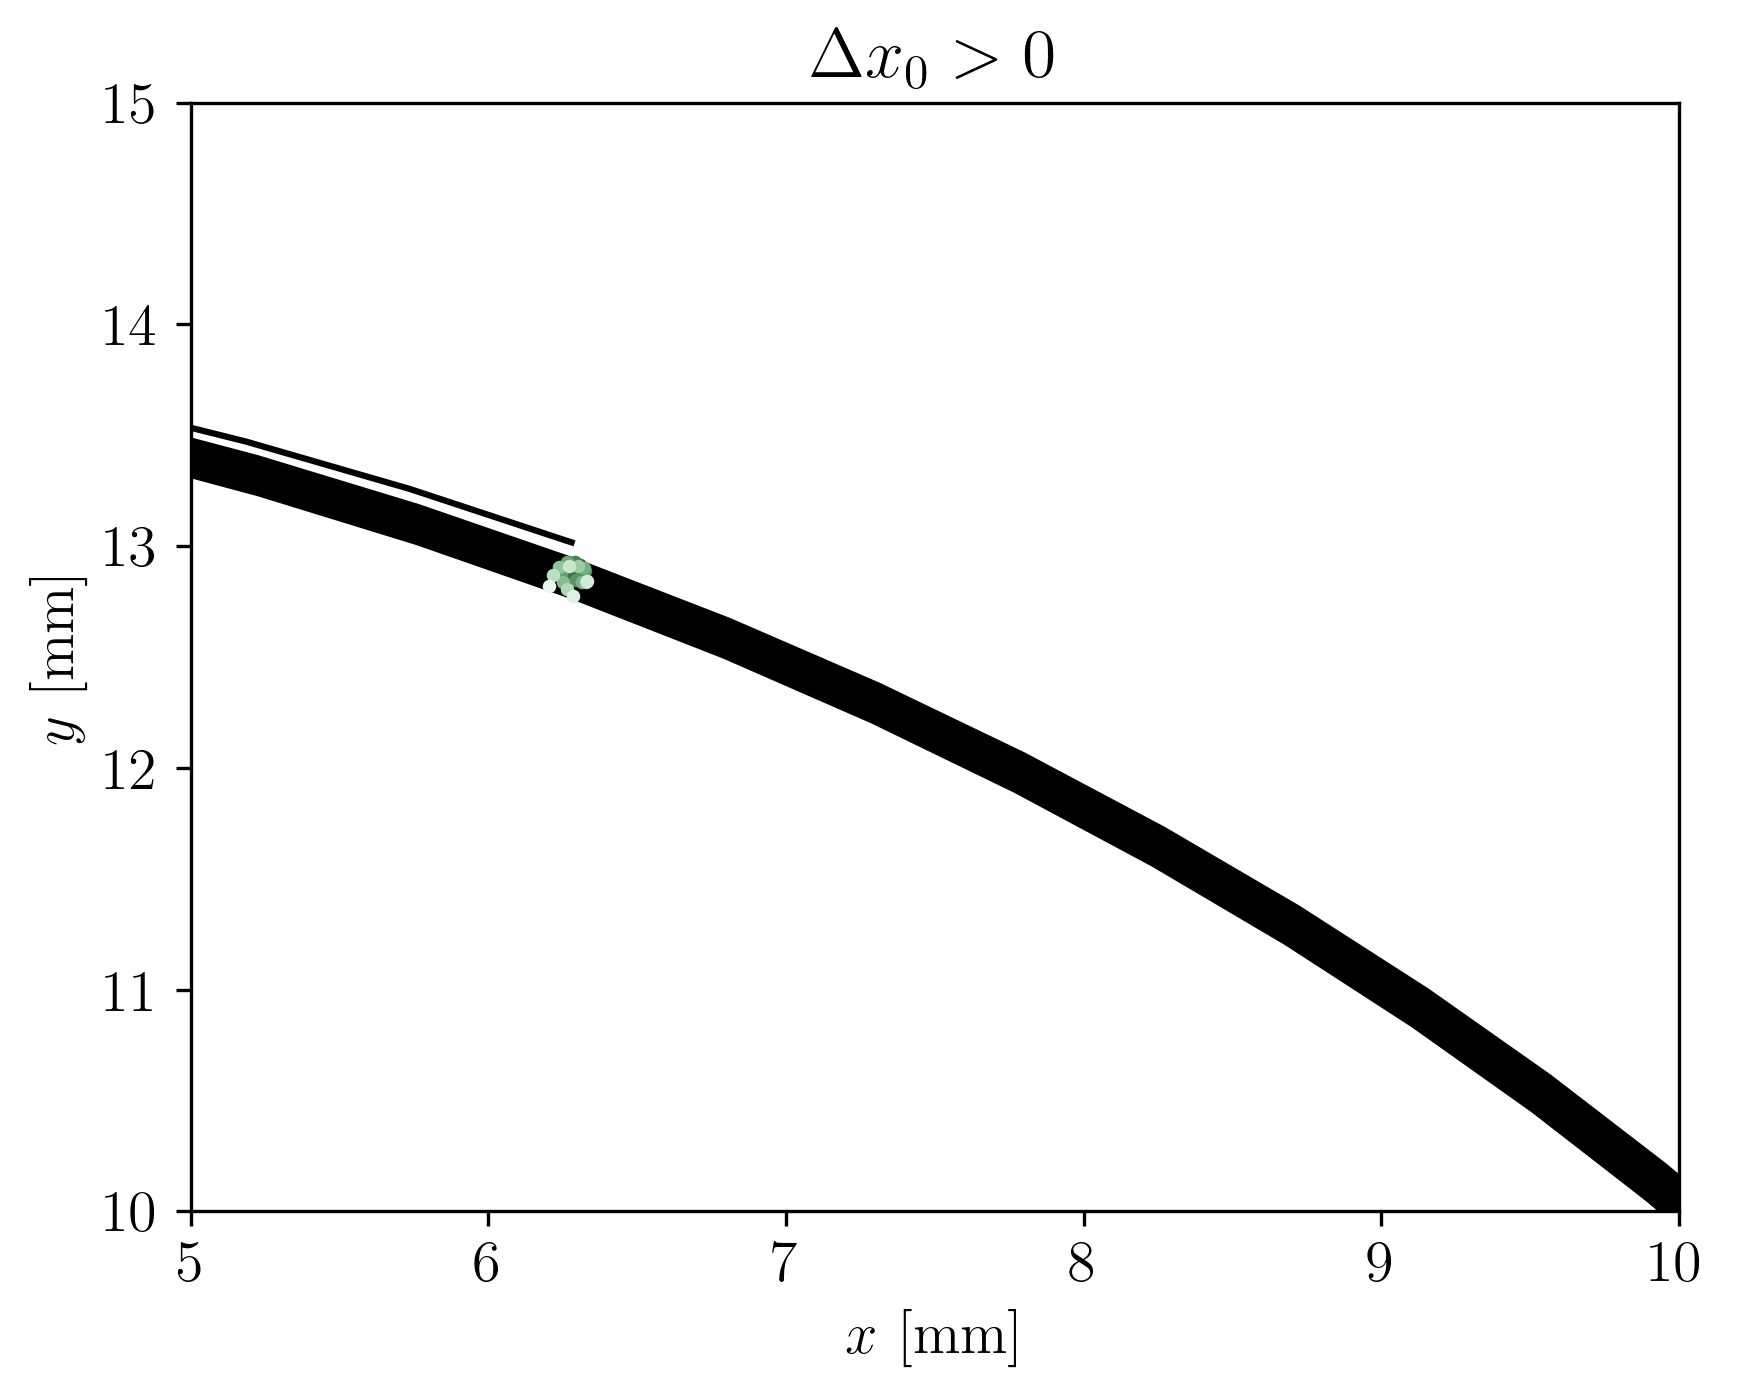

In [118]:
cmap = sns.cubehelix_palette(start=2, rot=0, dark=0, light=.95, reverse=True, as_cmap=True)
norm = matplotlib.colors.Normalize(vmin=0, vmax=29)
colors = cmap(norm(range(30)))
for i in range(30):
    plt.scatter(data_x_pos['x'].values[i*420],data_x_pos['y'].values[i*420], color=colors[i], s=5)
    # print(data_x_pos['z'].values[i*420])
plt.plot(data_x_neg_ref['x'].values, data_x_neg_ref['y'].values, zorder=-1, color='black')
plt.xlim((5,10))
plt.ylim((10,15))
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.title('$\Delta x_0 > 0$');

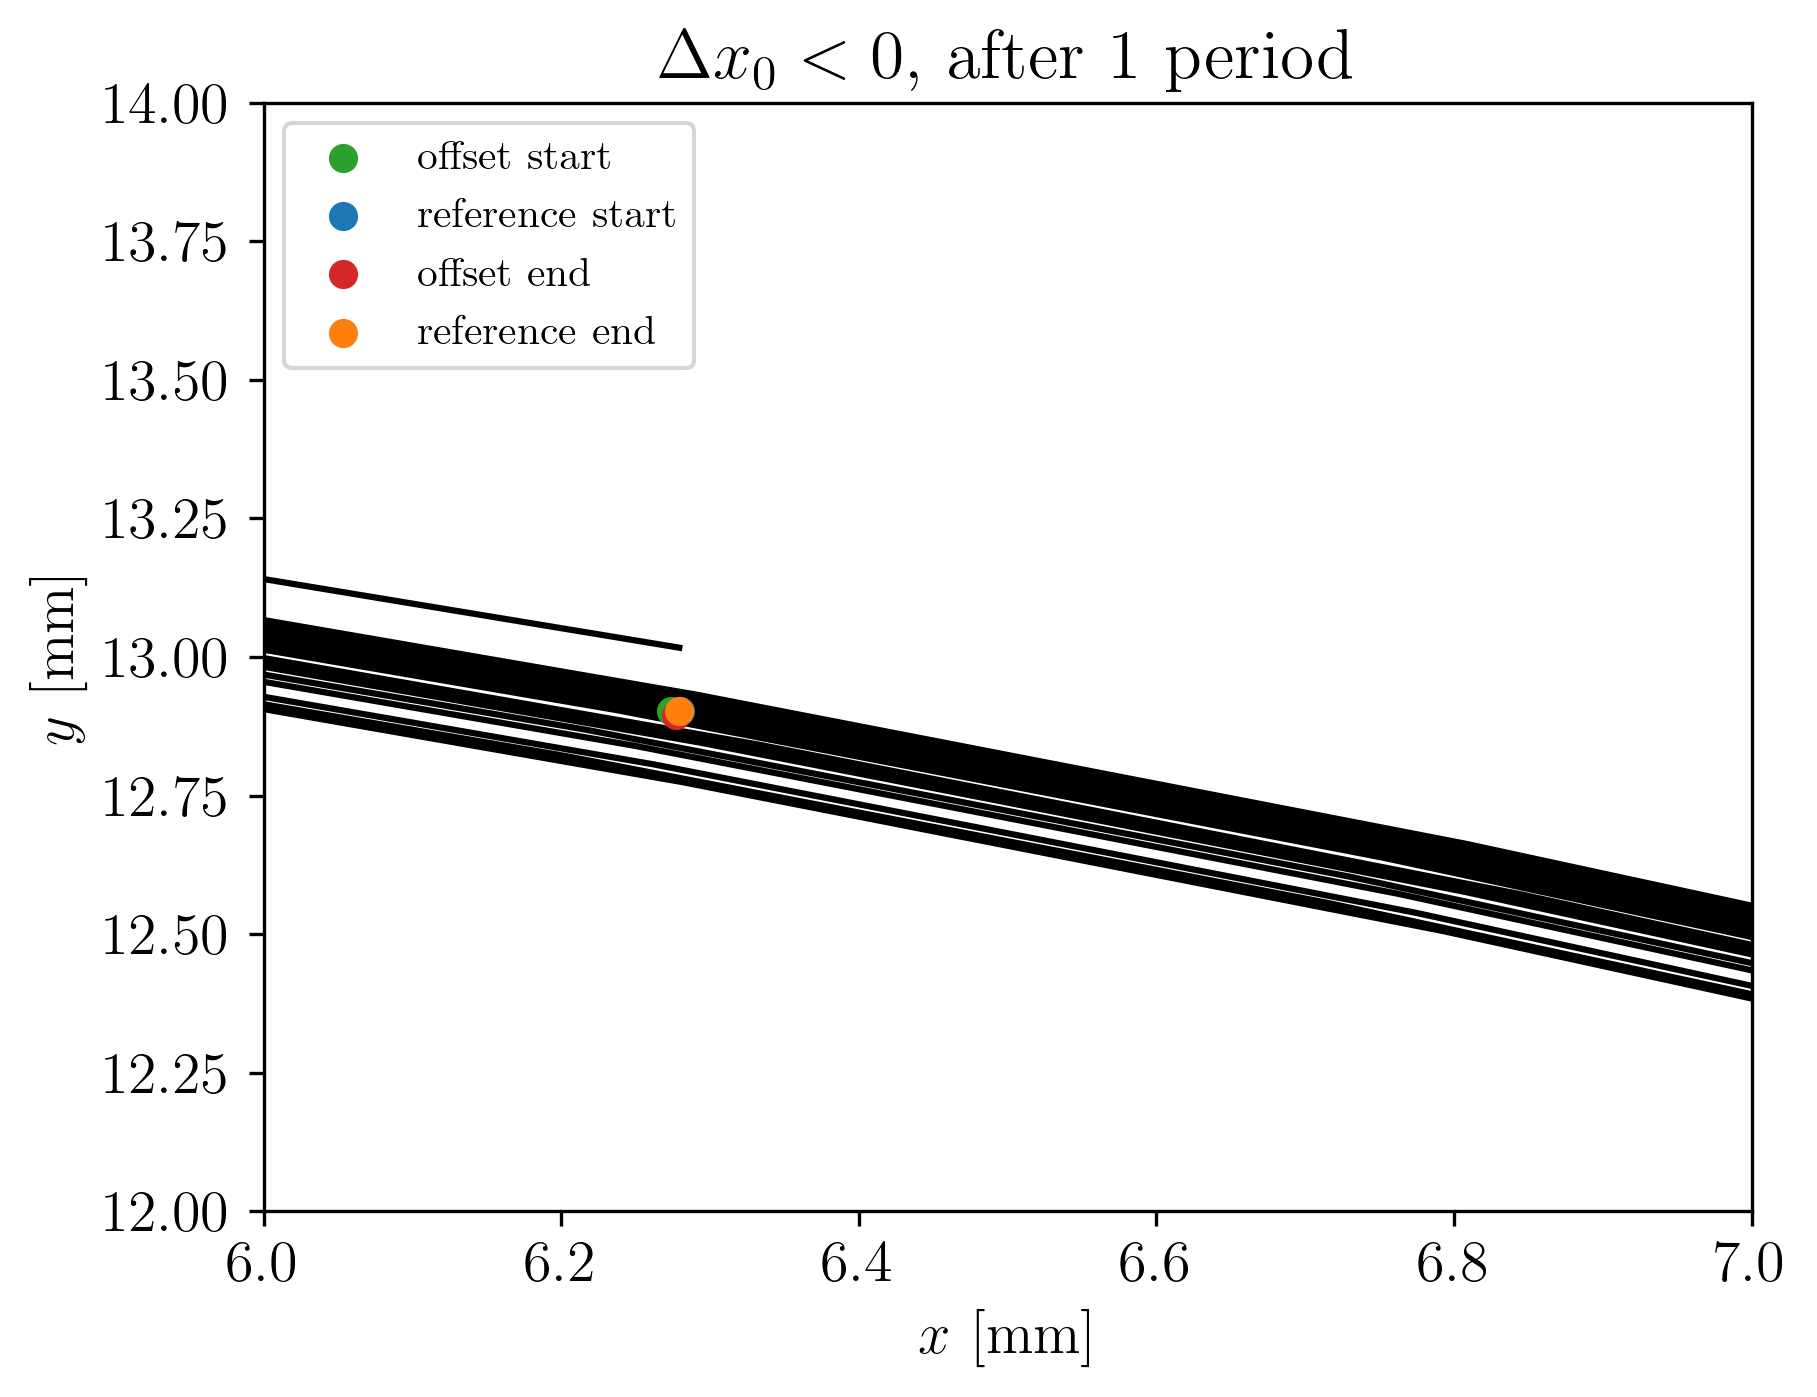

In [123]:
plt.scatter(data_x_neg['x'].values[0],data_x_neg['y'].values[0], label='offset start', color='tab:green')
plt.scatter(data_x_neg_ref['x'].values[0],data_x_neg_ref['y'].values[0], label='reference start')
plt.scatter(data_x_neg['x'].values[420],data_x_neg['y'].values[420], label = 'offset end', color='tab:red')
plt.scatter(data_x_neg_ref['x'].values[420],data_x_neg_ref['y'].values[420], label='reference end')
plt.plot(data_x_neg_ref['x'].values, data_x_neg_ref['y'].values, zorder=-1, color='black')
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim((6,7))
plt.ylim((12,14))
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 < 0$, after 1 period');

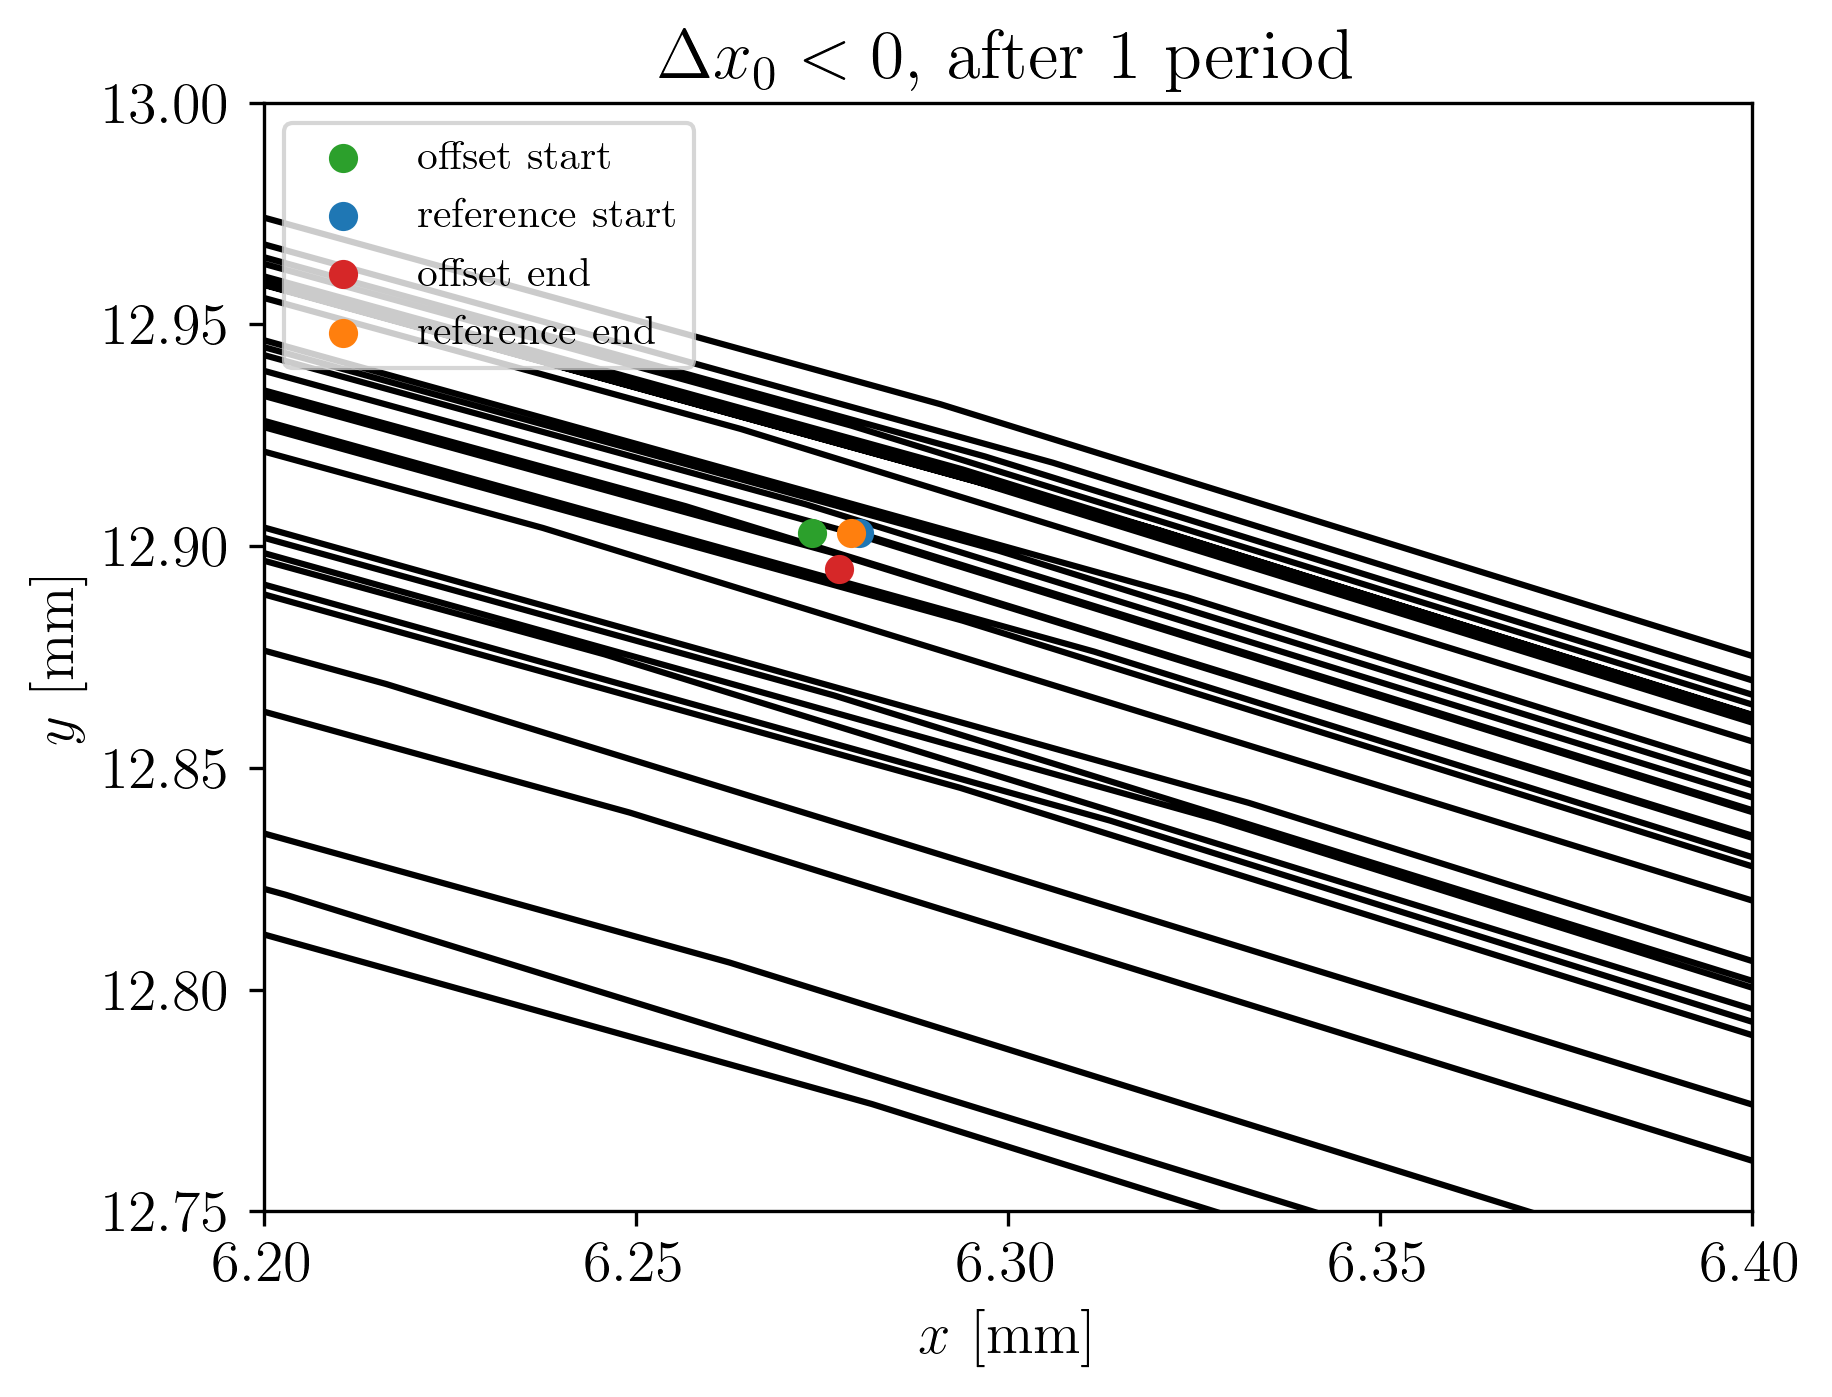

In [126]:
plt.scatter(data_x_neg['x'].values[0],data_x_neg['y'].values[0], label='offset start', color='tab:green')
plt.scatter(data_x_neg_ref['x'].values[0],data_x_neg_ref['y'].values[0], label='reference start')
plt.scatter(data_x_neg['x'].values[420],data_x_neg['y'].values[420], label = 'offset end', color='tab:red')
plt.scatter(data_x_neg_ref['x'].values[420],data_x_neg_ref['y'].values[420], label='reference end')
plt.plot(data_x_neg_ref['x'].values, data_x_neg_ref['y'].values, zorder=-1, color='black')
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim((6.2,6.4))
plt.ylim((12.75,13))
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 < 0$, after 1 period');

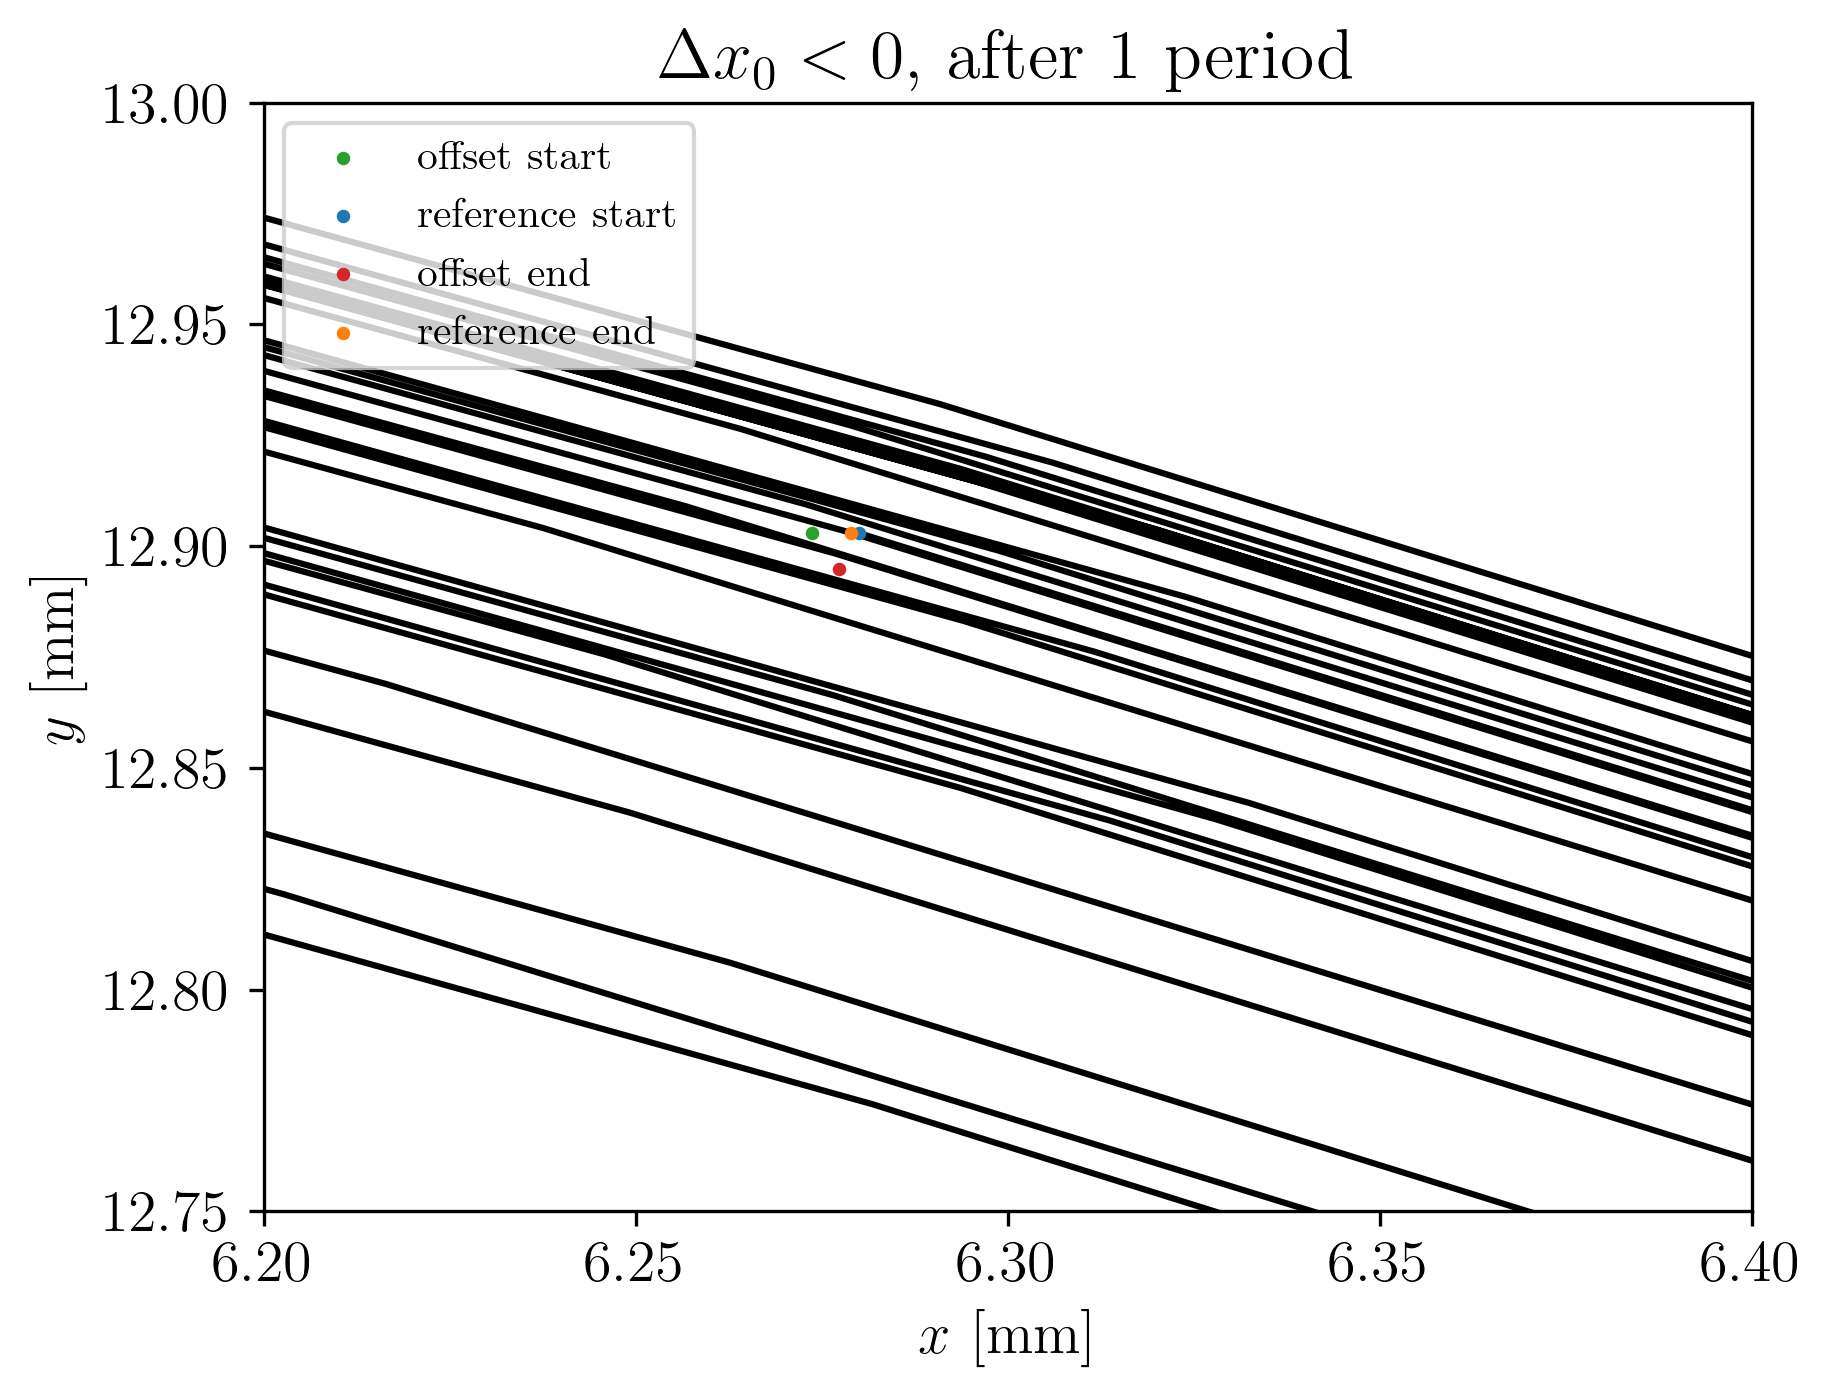

In [137]:
plt.scatter(data_x_neg['x'].values[0],data_x_neg['y'].values[0], label='offset start', color='tab:green', s=5)
plt.scatter(data_x_neg_ref['x'].values[0],data_x_neg_ref['y'].values[0], label='reference start', s=5)
plt.scatter(data_x_neg['x'].values[420],data_x_neg['y'].values[420], label = 'offset end', color='tab:red', s=5)
plt.scatter(data_x_neg_ref['x'].values[420],data_x_neg_ref['y'].values[420], label='reference end', s=5)
plt.plot(data_x_neg_ref['x'].values, data_x_neg_ref['y'].values, zorder=-1, color='black')
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim((6.2,6.4))
plt.ylim((12.75,13))
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 < 0$, after 1 period');

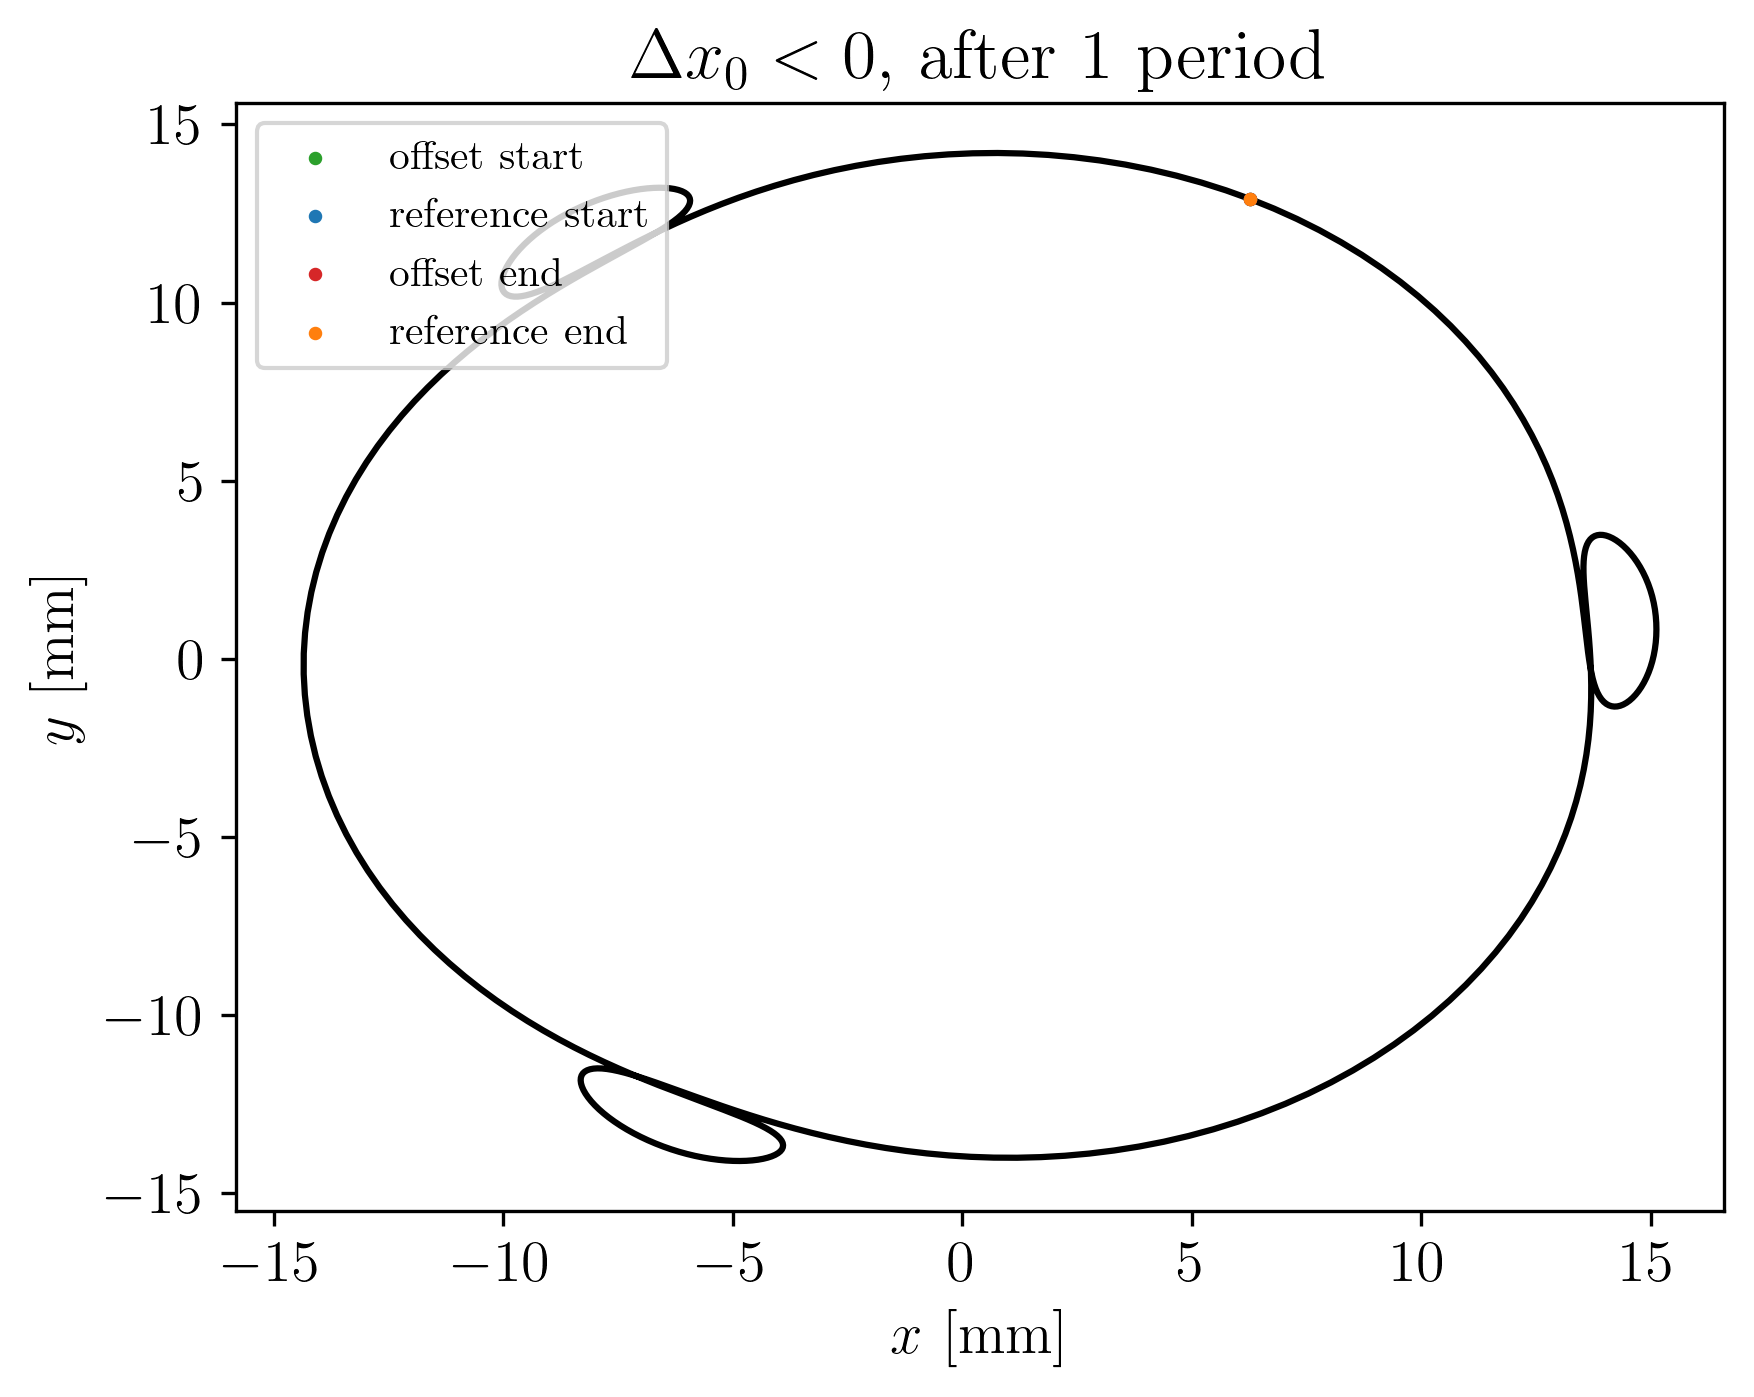

In [135]:
plt.scatter(data_x_neg['x'].values[0],data_x_neg['y'].values[0], label='offset start', color='tab:green', s=5)
plt.scatter(data_x_neg_ref['x'].values[0],data_x_neg_ref['y'].values[0], label='reference start', s=5)
plt.scatter(data_x_neg['x'].values[420],data_x_neg['y'].values[420], label = 'offset end', color='tab:red', s=5)
plt.scatter(data_x_neg_ref['x'].values[420],data_x_neg_ref['y'].values[420], label='reference end', s=5)
plt.plot(data_x_neg_ref['x'].values[:421], data_x_neg_ref['y'].values[:421], zorder=-1, color='black')
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 < 0$, after 1 period');

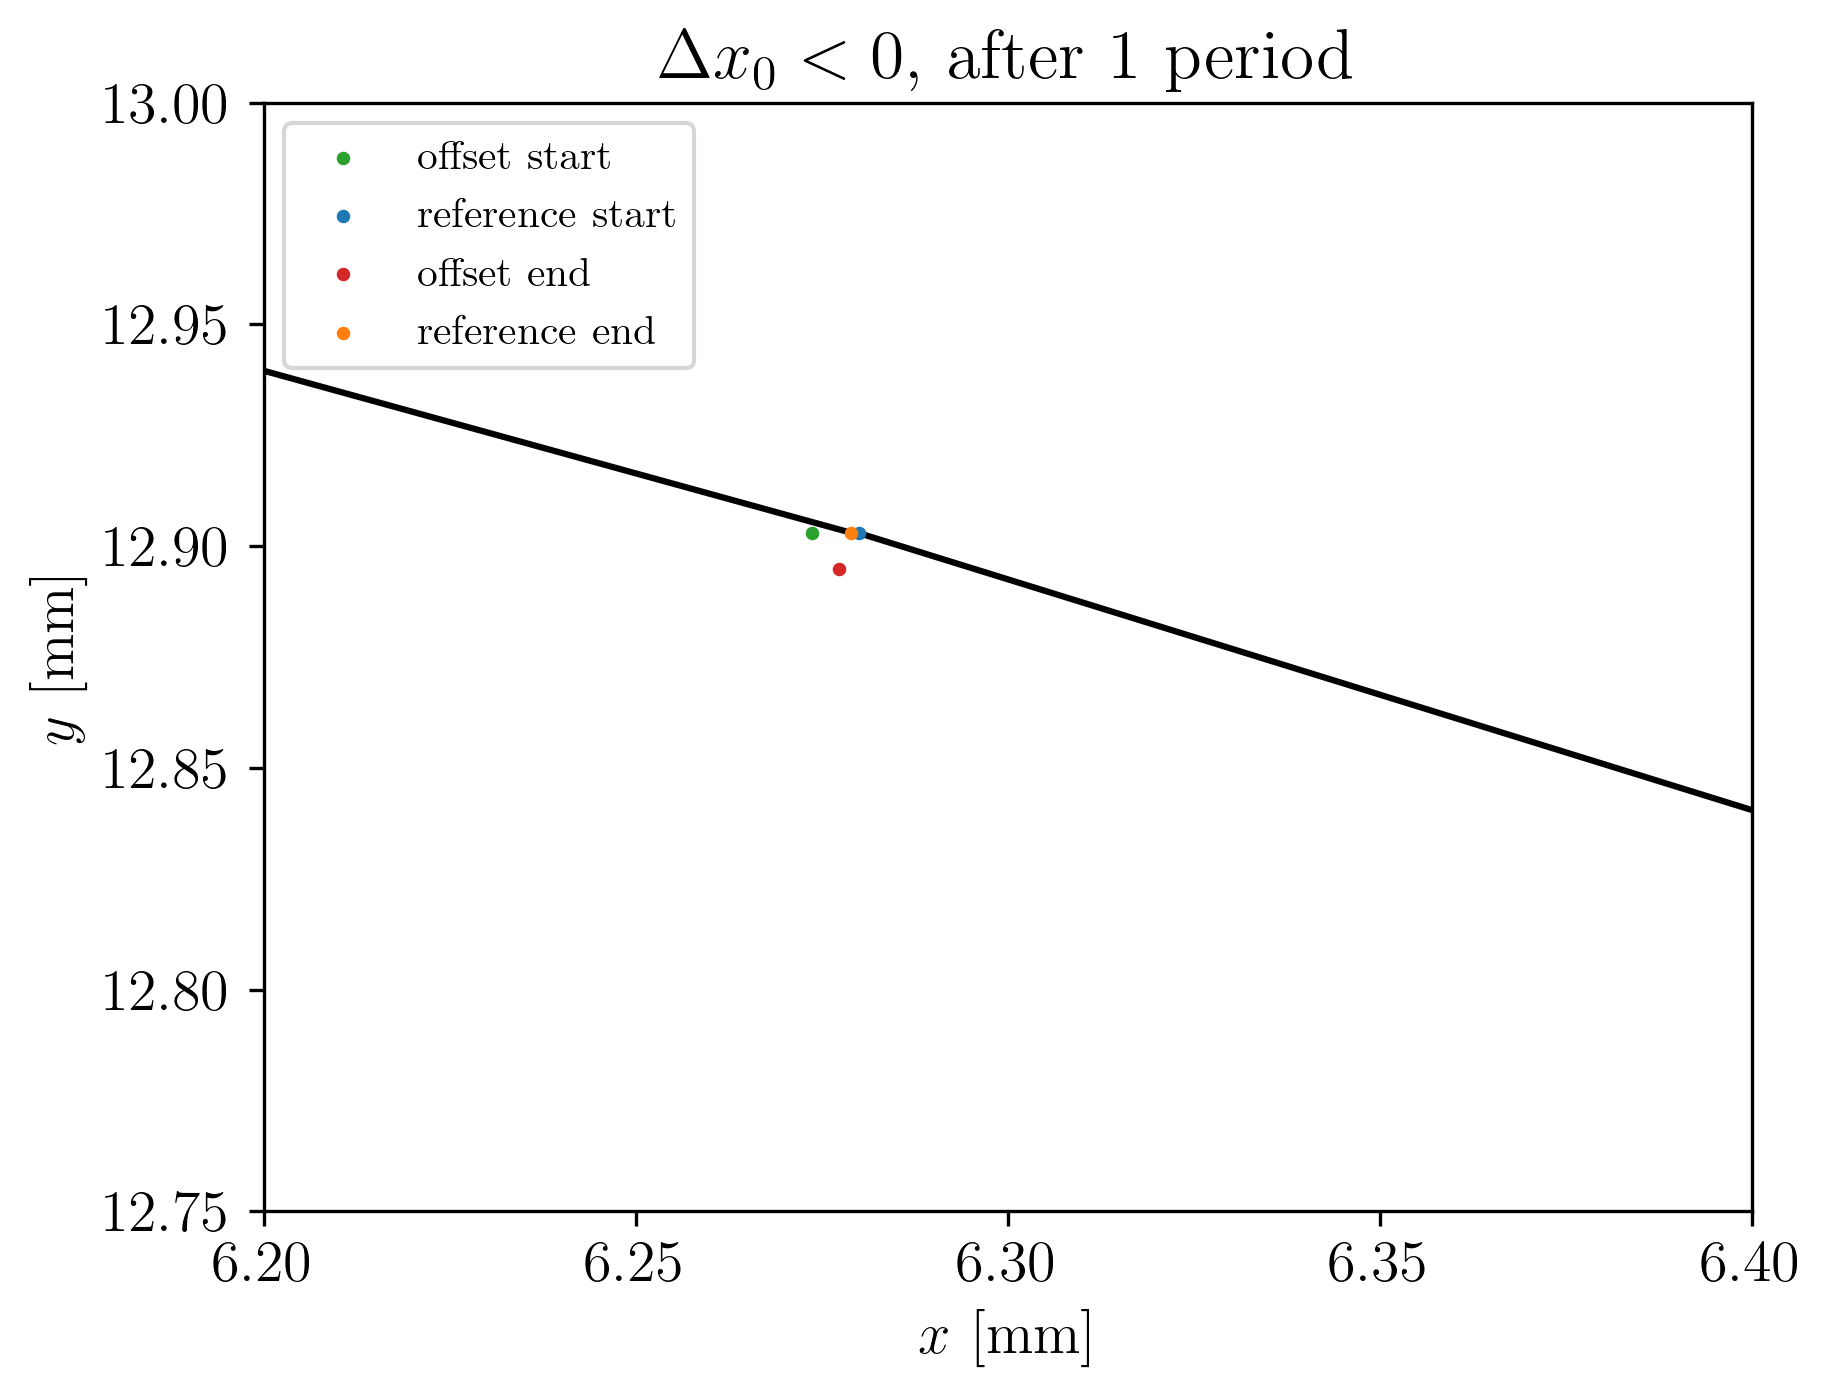

In [136]:
plt.scatter(data_x_neg['x'].values[0],data_x_neg['y'].values[0], label='offset start', color='tab:green', s=5)
plt.scatter(data_x_neg_ref['x'].values[0],data_x_neg_ref['y'].values[0], label='reference start', s=5)
plt.scatter(data_x_neg['x'].values[420],data_x_neg['y'].values[420], label = 'offset end', color='tab:red', s=5)
plt.scatter(data_x_neg_ref['x'].values[420],data_x_neg_ref['y'].values[420], label='reference end', s=5)
plt.plot(data_x_neg_ref['x'].values[:421], data_x_neg_ref['y'].values[:421], zorder=-1, color='black')
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim((6.2,6.4))
plt.ylim((12.75,13))
plt.legend(loc='upper left', fontsize=10)
plt.title('$\Delta x_0 < 0$, after 1 period');